# Assignment 3 — Code Submission (Qwen3-TTS)

**Submit:** this `.ipynb` file inside the required ZIP package, together with the required wav_examples/ folder.

**Group members (Name | ID):**
- `Adi Issa | a1987954`
- `Gaoyuan Chen | a1993974`
- `Zaid Ul Quadir Qazi | a1990366`

**Date:** `1 Nov 2026`

This notebook is the Qwen3-TTS part of our project: we fine-tune `Qwen/Qwen3-TTS-12Hz-0.6B-Base` on LJSpeech in four controlled experiments (learning rate × data size) and evaluate them with word error rate (WER), latency and real-time factor (RTF), using two deployment backends.

**Run on Google Colab with an A100 GPU.** Step 1 contains every manual action (notebook folder, Drive authorisation, switches); all later cells run unattended and every path is relative to the notebook folder. With the default switches the notebook repeats the whole study from scratch: learning-rate search, four training runs, evaluation on both backends and the demo (about a day of A100 time). Finished epochs and generated items are saved, so an interrupted session continues where it stopped. The four reported checkpoints (3.6 GB each) are too large for the submission: they are shared on Google Drive with the saved evaluation records (folder `GenAI_3_Checkpoints`: <https://drive.google.com/drive/folders/1gMHQJ8O9UIm3ZoDJEVk9b9s0HpJrW1Gh>), and `RUN_SEARCH = False` with `RUN_TRAINING = False` uses them instead of training (see *Marker instructions* at the end).



**1. Set the notebook folder and switches, authorise Drive and install dependencies.**

This is the only cell that needs user input. `NOTEBOOK_FOLDER` is the folder holding this notebook, `requirements.txt` and `qwen_report_data/` (leave it empty to use the current folder); a Drive folder is mounted automatically. `SHARED_FOLDER` is the shared Drive folder `GenAI_3_Checkpoints` (<https://drive.google.com/drive/folders/1gMHQJ8O9UIm3ZoDJEVk9b9s0HpJrW1Gh>) with the four reported checkpoints and the saved evaluation records; it is used only when `RUN_TRAINING = False`. The saved output below comes from the 30 Oct run, before `SHARED_FOLDER` was added.

In [1]:
# Step 1: the only cell that needs user input (notebook folder, Drive authorisation and switches).
import os, sys, platform, shutil, subprocess
from pathlib import Path
from importlib.metadata import version

NOTEBOOK_FOLDER = ""      # folder holding this notebook, requirements.txt and qwen_report_data/; "" = current folder
                          # on Colab: the Drive copy of this folder, e.g. "/content/drive/MyDrive/Qwen3TTS"
RUN_SEARCH = True         # nine-candidate learning-rate search (many A100 hours)
RUN_TRAINING = True       # four 20-epoch fine-tuning runs (about 6 A100 hours)
RUN_EVALUATION = True     # generate and score every missing evaluation item on both backends
RUN_DEMO = True           # synthesise one new sentence
INFERENCE_BACKEND = "optimized"   # main backend: "optimized" (vLLM-Omni) or "eager" (PyTorch)
SHARED_FOLDER = "/content/drive/MyDrive/GenAI_3_Checkpoints"   # shared reported checkpoints + evaluation records
                          # Drive shortcut of https://drive.google.com/drive/folders/1gMHQJ8O9UIm3ZoDJEVk9b9s0HpJrW1Gh
                          # (see Marker instructions); used only when RUN_TRAINING = False
GPU_WORK = RUN_SEARCH or RUN_TRAINING or RUN_EVALUATION or RUN_DEMO

SHARED_DIR = None if RUN_TRAINING or not SHARED_FOLDER else Path(SHARED_FOLDER)
if NOTEBOOK_FOLDER.startswith("/content/drive") or (SHARED_DIR and SHARED_FOLDER.startswith("/content/drive")):
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_ROOT = Path(NOTEBOOK_FOLDER or ".").resolve()
REPORT_DIR = PROJECT_ROOT / "qwen_report_data"       # shipped inputs: split manifests, vLLM-Omni package list, recorded runs
RUN_DIR = PROJECT_ROOT / "evaluation"                # generated audio, timings and scores (one folder per backend)
RESULTS_DIR = PROJECT_ROOT / "results"               # tables written by this notebook
WAV_DIR = PROJECT_ROOT / "wav_examples"              # labelled WAVs for the submission ZIP
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"        # codec-token cache, search and training checkpoints
LJSPEECH_ARCHIVE = PROJECT_ROOT / "LJSpeech-1.1.tar.bz2"   # downloaded in step 2 if absent
DATA_ROOT = Path(os.environ.get("LJSPEECH_ROOT", "/content/LJSpeech-1.1"))   # local copy for fast audio access

if not ((PROJECT_ROOT / "requirements.txt").is_file() and REPORT_DIR.is_dir()):
    raise FileNotFoundError(f"requirements.txt and qwen_report_data/ not found in {PROJECT_ROOT}: set NOTEBOOK_FOLDER.")
for folder in (RUN_DIR, RESULTS_DIR, WAV_DIR, CHECKPOINT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
if SHARED_DIR is not None:
    if not (SHARED_DIR / "checkpoints").is_dir():
        raise FileNotFoundError(f"{SHARED_DIR / 'checkpoints'} not found: add the shared folder to My Drive or set SHARED_FOLDER.")
    if (SHARED_DIR / "evaluation").is_dir() and not (RUN_DIR / "optimized" / "state").is_dir():
        shutil.copytree(SHARED_DIR / "evaluation", RUN_DIR, dirs_exist_ok=True)   # saved vLLM-Omni items (0.9 GB)
os.environ.update(HF_HUB_DISABLE_IMPLICIT_TOKEN="1", TOKENIZERS_PARALLELISM="false")

if GPU_WORK:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_ROOT / "requirements.txt")], check=True)
    if not shutil.which("sox"):
        subprocess.run("apt-get -qq update && apt-get install -y -qq sox ffmpeg", shell=True, check=True, capture_output=True)
    import numpy, torch
    if numpy.__version__ != "2.0.2":
        raise RuntimeError("numpy changed during installation: restart the session and run Step 1 again.")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime (A100) for training, evaluation or the demo.")
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB)",
          "| torch", torch.__version__, "| CUDA", torch.version.cuda)
print("Python", platform.python_version(), "|", ", ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scikit-learn")))
print("READY:", "GPU stages enabled" if GPU_WORK else "saved results only (CPU)")

Mounted at /content/drive
GPU: NVIDIA A100-SXM4-40GB (39 GB) | torch 2.11.0+cu128 | CUDA 12.8
Python 3.12.13 | numpy 2.0.2, pandas 2.2.2, scikit-learn 1.6.1
READY: GPU stages enabled


# 1.1 Dataset handling & pre-processing (Rubric 1.1)

## 1.1.1 Dataset location and structure
- **Dataset:** LJSpeech 1.1 — 13,100 clips of one female speaker, 22.05 kHz ([link](https://keithito.com/LJ-Speech-Dataset/))
- **Local path used:** `LJSpeech-1.1.tar.bz2` in the notebook folder (downloaded from the link above if absent), extracted to `/content/LJSpeech-1.1`
- **Files/folders used:**
  - `metadata.csv`
  - `wavs/`

## 1.1.2 Audio preprocessing (document your choices)
- **Sampling rate:** the Qwen 12 Hz speech tokenizer encodes the original 22.05 kHz clips at 24 kHz; generated speech is 24 kHz and is resampled to 16 kHz only for Whisper scoring.
- **Silence trimming / padding:** no trimming, so the model keeps LJSpeech's natural pauses; batches are right-padded and padding is masked out of the loss.
- **Any filtering / normalization:** none — all clips (1.1–10.1 s) are usable by the tokenizer.
- **Speaker reference:** one fixed clip, `LJ043-0158`, provides the speaker embedding for every model. It belongs to the 2k training set only.

## 1.1.3 Text preprocessing (minimum: justify your choice)
- **Normalization:** LJSpeech `normalised_text` (numbers already written as words) → ASCII → group abbreviation list (`Mr.` → `mister`, …) → lower case → quotes/brackets removed, `- ; :` replaced by spaces. New prompts containing digits first pass through NeMo number normalisation.
- **Tokenizer / phonemizer (if used):** the pinned Qwen3-TTS text tokenizer; no phonemizer, because the pretrained model reads graphemes.

## 1.1.4 Train/validation/test split (reproducible)
- **Split ratio:** 80/10/10
- **Seed:** 42 (pandas sampling and scikit-learn `train_test_split`)
- **How split is created:** sample 2,000 utterances, split them 80/10/10, then sample the 1,000-utterance subset inside each role.
- **Any subset used:** 2k = 1600/200/200 and nested 1k = 800/100/100. The 1k test set is **CommonTest**, shared by all five models.

**2. Load LJSpeech.**

In [2]:
import csv, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, HTML, display

if not (DATA_ROOT / "metadata.csv").is_file():      # copy (or download) the archive once, then read audio from local disk
    archive = DATA_ROOT.parent / LJSPEECH_ARCHIVE.name
    archive.parent.mkdir(parents=True, exist_ok=True)
    if LJSPEECH_ARCHIVE.is_file():
        shutil.copy(LJSPEECH_ARCHIVE, archive)
    else:
        subprocess.run(["wget", "-q", "-O", str(archive), "https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2"], check=True)
    subprocess.run(["tar", "-xjf", str(archive), "-C", str(DATA_ROOT.parent)], check=True)
data = pd.read_csv(DATA_ROOT / "metadata.csv", sep="|", names=["utt_id", "raw_text", "normalised_text"],
                   quoting=csv.QUOTE_NONE)
data["wav_path"] = "wavs/" + data.utt_id + ".wav"
assert len(data) == 13100 and data.utt_id.is_unique and data.notna().all().all()
print("Utterances:", len(data), "| WAV files:", len(list((DATA_ROOT / "wavs").glob("*.wav"))))
display(data[["utt_id", "raw_text", "normalised_text"]].head(3))

Utterances: 13100 | WAV files: 13100


,utt_id,raw_text,normalised_text
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ..."
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...


**3. Clean the text.**

In [3]:
from functools import lru_cache
from unidecode import unidecode

ABBREVIATIONS = {   # shared group list ("Misess" is kept unchanged for consistency with all saved runs)
    "Mr.": "Mister", "Mrs.": "Misess", "Dr.": "Doctor", "No.": "Number", "St.": "Saint", "Co.": "Company",
    "Jr.": "Junior", "Maj.": "Major", "Gen.": "General", "Drs.": "Doctors", "Rev.": "Reverend",
    "Lt.": "Lieutenant", "Hon.": "Honorable", "Sgt.": "Sergeant", "Capt.": "Captain", "Esq.": "Esquire",
    "Ltd.": "Limited", "Col.": "Colonel", "Ft.": "Fort",
}

@lru_cache(maxsize=1)
def number_normalizer():
    # NVIDIA NeMo text processing: https://github.com/NVIDIA/NeMo-text-processing
    from nemo_text_processing.text_normalization.normalize import Normalizer
    return Normalizer(lang="en", input_case="cased")

def clean_text(text, numbers=False):
    """ASCII, optional number expansion, abbreviations, lower case and spoken punctuation only."""
    text = unidecode(text)
    if numbers:                         # LJSpeech normalised_text already spells numbers out
        text = number_normalizer().normalize(text)
    for short, full in ABBREVIATIONS.items():
        text = text.replace(short, full)
    text = text.lower()
    for symbol in '"()[]':
        text = text.replace(symbol, "")
    for symbol in "-;:":
        text = text.replace(symbol, " ")
    return " ".join(text.split())

data["text"] = data.normalised_text.map(clean_text)
display(data.loc[data.normalised_text.str.contains(r'Mr\.|;|"'), ["utt_id", "normalised_text", "text"]].head(3))

,utt_id,normalised_text,text
6,LJ001-0007,"the earliest book printed with movable types, ...","the earliest book printed with movable types, ..."
10,LJ001-0011,it is of the first importance that the letter ...,it is of the first importance that the letter ...
18,LJ001-0019,and which developed more completely and satisf...,and which developed more completely and satisf...


**4. Create the seed-42 splits.**

In [4]:
from sklearn.model_selection import train_test_split

def make_splits(frame, seed=42):
    """2,000 utterances split 80/10/10; the 1k subset is sampled inside each 2k role (nested and disjoint)."""
    sample = frame.sample(n=2000, random_state=seed).reset_index(drop=True)
    train, rest = train_test_split(sample, test_size=0.2, random_state=seed, shuffle=True)
    val, test = train_test_split(rest, test_size=0.5, random_state=seed, shuffle=True)
    splits = {}
    for role, part in (("train", train), ("val", val), ("test", test)):
        part = part.reset_index(drop=True)
        splits["2k", role] = part
        splits["1k", role] = part.sample(n=len(part) // 2, random_state=seed).reset_index(drop=True)
    return {key: part[["utt_id", "text", "wav_path"]].to_dict("records") for key, part in splits.items()}

SPLITS = make_splits(data)
for (scale, role), rows in SPLITS.items():          # identical to the manifests used by every saved run
    saved = [json.loads(line) for line in open(REPORT_DIR / "manifests" / f"{scale}_{role}.jsonl", encoding="utf-8")]
    assert rows == saved, f"{scale} {role} differs from the saved split"
ids = {key: {row["utt_id"] for row in rows} for key, rows in SPLITS.items()}
for scale in ("1k", "2k"):
    assert not (ids[scale, "train"] & ids[scale, "val"] or ids[scale, "train"] & ids[scale, "test"]
                or ids[scale, "val"] & ids[scale, "test"])
assert all(ids["1k", role] <= ids["2k", role] for role in ("train", "val", "test"))
assert [key for key, members in ids.items() if "LJ043-0158" in members] == [("2k", "train")]
display(pd.DataFrame([dict(subset=s, role=r, utterances=len(v)) for (s, r), v in SPLITS.items()])
        .pivot(index="subset", columns="role", values="utterances")[["train", "val", "test"]])
print("Seed 42: the splits match the saved manifests; roles are disjoint and the 1k subset is nested in the 2k subset.")
print("Speaker reference LJ043-0158 is only in the 2k training set.")

role,train,val,test
subset,,,
1k,800,100,100
2k,1600,200,200


Seed 42: the splits match the saved manifests; roles are disjoint and the 1k subset is nested in the 2k subset.
Speaker reference LJ043-0158 is only in the 2k training set.


**5. Sanity checks: clip durations, sentence lengths and characters.**

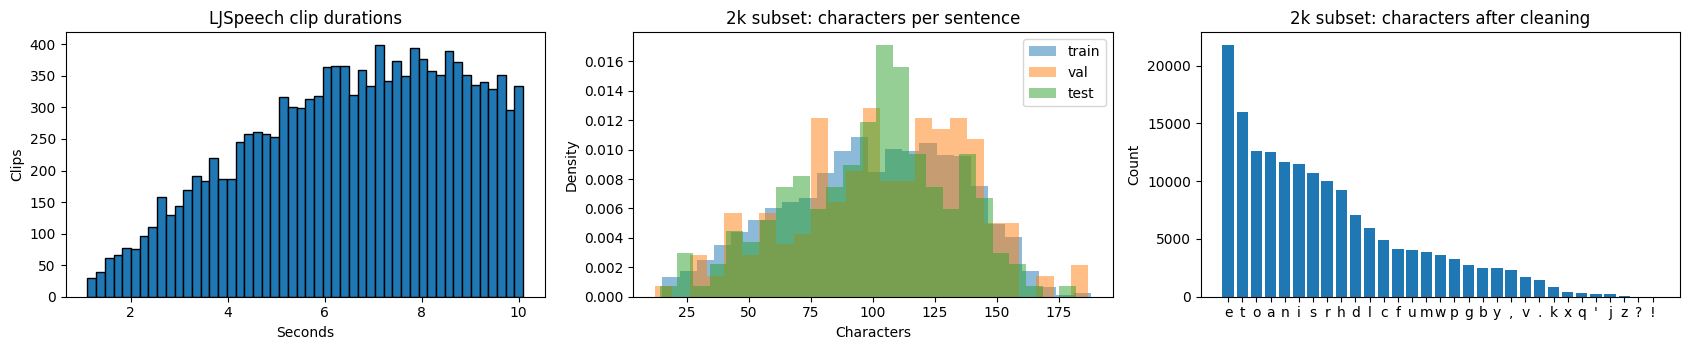

count    13100.00
mean         6.57
std          2.19
min          1.11
25%          4.99
50%          6.76
75%          8.39
max         10.10
Characters other than a-z after cleaning: ! ' , . ?


In [5]:
data["duration"] = [sf.info(str(DATA_ROOT / path)).duration for path in data.wav_path]
subset = pd.DataFrame([dict(row, role=role) for (scale, role), rows in SPLITS.items() if scale == "2k" for row in rows])
chars = pd.Series(list("".join(subset.text).replace(" ", ""))).value_counts()

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
axes[0].hist(data.duration, bins=50, edgecolor="black")
axes[0].set(title="LJSpeech clip durations", xlabel="Seconds", ylabel="Clips")
for role in ("train", "val", "test"):
    axes[1].hist(subset[subset.role == role].text.str.len(), bins=25, alpha=0.5, density=True, label=role)
axes[1].set(title="2k subset: characters per sentence", xlabel="Characters", ylabel="Density")
axes[1].legend()
axes[2].bar(chars.index, chars.values)
axes[2].set(title="2k subset: characters after cleaning", ylabel="Count")
plt.tight_layout()
plt.show()
print(data.duration.describe().round(2).to_string())
print("Characters other than a-z after cleaning:", " ".join(sorted(c for c in chars.index if not c.isalpha())))

# 1.2 End-to-end TTS pipeline implementation (Rubric 1.2)

## 1.2.1 Pipeline overview (high level)
- **TTS approach:** fine-tune the pretrained Qwen3-TTS 0.6B Base model ([model card](https://huggingface.co/Qwen/Qwen3-TTS-12Hz-0.6B-Base), [code](https://github.com/QwenLM/Qwen3-TTS)) on LJSpeech.
- **Key components:**
  - Text front-end: `clean_text()` and the Qwen text tokenizer
  - Acoustic model: the Qwen3-TTS **Talker** (905,788,672 parameters, fully fine-tuned) predicts 16 codec codebooks at 12.5 frames/s, conditioned on a fixed x-vector speaker embedding
  - Vocoder / waveform generator: the frozen Qwen 12 Hz speech-tokenizer decoder
- **Output:** playable mono 24 kHz PCM16 `.wav`
- **Two inference backends** (same checkpoints and sampling settings):
  - **PyTorch eager** — the reference `qwen-tts` implementation (Hugging Face Transformers `generate` in PyTorch eager mode); returns the complete waveform.
  - **vLLM-Omni** — a local [vLLM-Omni](https://github.com/vllm-project/vllm-omni) server: the Talker runs in vLLM with `torch.compile` and CUDA Graphs, the codec decoder with CUDA Graphs, and audio is streamed in PCM chunks (first packet = 4 codec frames = 320 ms of speech).

```
text → clean_text → Qwen tokenizer → Talker (+ speaker embedding) → 16-codebook codec tokens → speech-tokenizer decoder → 24 kHz WAV
```

## 1.2.2 Environment & dependencies (reproducible)
- **OS:** Google Colab (Linux)
- **Python:** 3.12
- **CUDA (if used):** 12.8 (training and PyTorch eager inference); 12.9 inside the isolated vLLM-Omni environment
- **GPU (if used):** NVIDIA A100-SXM4 40 GB; FP32 weights and optimizer state with BF16 compute
- **Dependencies:** `requirements.txt` (pinned); vLLM-Omni uses `qwen_report_data/runtime/engine_requirements.txt`. Step 1 prints the versions actually used.

## 1.2.3 Training command(s)
Training runs inside this notebook (Section 1.3) when `RUN_TRAINING = True`:
```python
run_experiment("expA")   # selected LR (2e-7 in the recorded run), 1k subset
run_experiment("expB")   # other finalist LR (5e-7), 1k subset
run_experiment("expC")   # selected LR, 2k subset
run_experiment("expD")   # other finalist LR, 2k subset
```

## 1.2.4 Inference: a single "text → wav" entrypoint (must be easy to run)
```python
text_to_wav("Any sentence you like.", "expC", WAV_DIR / "my_sentence.wav")   # label: Base, expA, expB, expC or expD
```
Defined in step 10 and demonstrated in step 24 (after evaluation, so it uses the checkpoints trained in this notebook).
- **Checkpoints:** each experiment's `best.pt`, written by training to `checkpoints/<model>/best.pt`; its SHA-256 is part of every evaluation identity. Base weights download from Hugging Face at a pinned revision.
- **Generated wavs:** `WAV_DIR` (`wav_examples/` in the notebook folder).

**6. Model configuration and helpers.**

In [6]:
import gc, hashlib, math, random, time
from contextlib import nullcontext
from dataclasses import dataclass, asdict

MODEL_ID = "Qwen/Qwen3-TTS-12Hz-0.6B-Base"
MODEL_REVISION = "5d83992436eae1d760afd27aff78a71d676296fc"      # pinned Hugging Face revision
SOURCE_REVISION = "022e286b98fbec7e1e916cb940cdf532cd9f488e"     # pinned github.com/QwenLM/Qwen3-TTS commit
LOSS_VERSION = "aligned_ce_previous_frame_v1"
REFERENCE_WAV = DATA_ROOT / "wavs/LJ043-0158.wav"
REFERENCE_SHA256 = "0ef94894c398fba57b9b90f11aff46deb2ed70736fe58092b3981bcef850c2d8"
GENERATION_SETTINGS = dict(do_sample=True, top_k=50, top_p=1.0, temperature=0.9, repetition_penalty=1.05,
    subtalker_dosample=True, subtalker_top_k=50, subtalker_top_p=1.0, subtalker_temperature=0.9, max_new_tokens=2048)

@dataclass
class BackendConfig:
    model_dir: str
    device: str = "cuda"
    dtype: str = "bfloat16"            # compute dtype; weights and optimizer state stay float32
    seed: int = 42
    micro_batch_size: int = 2
    gradient_accumulation: int = 4
    epochs: int = 20
    weight_decay: float = 0.01
    adam_betas: tuple = (0.9, 0.999)
    adam_eps: float = 1e-8
    gradient_checkpointing: bool = True
    residual_loss_weight: float = 0.3
    max_new_tokens: int = 2048

    @property
    def effective_batch_size(self):
        return self.micro_batch_size * self.gradient_accumulation

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)

@lru_cache(maxsize=1)
def model_files():
    """Pinned Base weights, text tokenizer and speech tokenizer from Hugging Face."""
    from huggingface_hub import snapshot_download
    return Path(snapshot_download(MODEL_ID, revision=MODEL_REVISION, token=False))

if GPU_WORK:
    import torch
    import torch.nn.functional as F
    from torch.utils.data import DataLoader
    if file_sha256(REFERENCE_WAV) != REFERENCE_SHA256:
        raise ValueError("LJ043-0158.wav differs from the reference used by all saved runs.")

**7. Batches and the training loss.**

`collate_items` builds Qwen's two-channel input (text tokens and codec tokens) in the same layout the model uses for non-streaming generation, with the speaker embedding at position 6. The loss is the cross-entropy of the first codebook plus 0.3 × the cross-entropy of the 15 residual codebooks; each residual frame is predicted from the previous hidden state, and padding is masked out.

In [7]:
class QwenDataset:
    """Rows with text and prepared audio codes (frames × 16 codebooks)."""
    def __init__(self, records, processor):
        self.items = []
        for record in records:
            wrapped = f"<|im_start|>assistant\n{record['text']}<|im_end|>\n<|im_start|>assistant\n"
            text_ids = processor(text=wrapped, return_tensors="pt", padding=True)["input_ids"]
            if text_ids.ndim == 1:
                text_ids = text_ids.unsqueeze(0)
            codes = torch.as_tensor(record["audio_codes"], dtype=torch.long)
            if codes.ndim != 2 or codes.shape[1] != 16 or not len(codes):
                raise ValueError(f"Invalid codec tokens: {record['audio_id']}")
            self.items.append({"text_ids": text_ids[:, :-5], "audio_codes": codes, "audio_id": record["audio_id"]})

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

def collate_items(items, config):
    """Text and codec channels with Qwen's non-streaming prefix; right padding is excluded from the loss."""
    length = max(x["text_ids"].shape[1] + len(x["audio_codes"]) for x in items) + 8
    size = len(items)
    batch = {
        "input_ids": torch.zeros(size, length, 2, dtype=torch.long),
        "codec_ids": torch.zeros(size, length, 16, dtype=torch.long),
        "text_embedding_mask": torch.zeros(size, length, 1, dtype=torch.bool),
        "codec_embedding_mask": torch.zeros(size, length, 1, dtype=torch.bool),
        "codec_mask": torch.zeros(size, length, dtype=torch.bool),
        "attention_mask": torch.zeros(size, length, dtype=torch.long),
        "codec_0_labels": torch.full((size, length), -100, dtype=torch.long),
    }
    tc = config.talker_config
    for i, item in enumerate(items):
        ids, codes = item["text_ids"][0], item["audio_codes"]
        n, frames = len(ids), len(codes)
        start, end = n + 7, n + 7 + frames
        text_channel, codec_channel = batch["input_ids"][i, :, 0], batch["input_ids"][i, :, 1]
        text_channel[:3] = ids[:3]
        text_channel[3:7] = config.tts_pad_token_id
        text_channel[7] = config.tts_bos_token_id
        text_channel[8:n + 5] = ids[3:]
        text_channel[n + 5] = config.tts_eos_token_id
        text_channel[n + 6:end + 1] = config.tts_pad_token_id
        codec_channel[3:8] = torch.tensor([tc.codec_nothink_id, tc.codec_think_bos_id, tc.codec_think_eos_id, 0, tc.codec_pad_id])
        codec_channel[8:n + 6] = tc.codec_pad_id
        codec_channel[n + 6] = tc.codec_bos_id
        codec_channel[start:end] = codes[:, 0]
        codec_channel[end] = tc.codec_eos_token_id
        batch["codec_0_labels"][i, start:end] = codes[:, 0]
        batch["codec_0_labels"][i, end] = tc.codec_eos_token_id
        batch["codec_ids"][i, start:end] = codes
        batch["codec_mask"][i, start:end] = True
        batch["text_embedding_mask"][i, :end + 1] = True
        batch["codec_embedding_mask"][i, 3:end + 1] = True
        batch["codec_embedding_mask"][i, 6] = False          # position 6 holds the speaker embedding
        batch["attention_mask"][i, :end + 1] = 1
    return batch

def forward_losses(model, batch, reference_embedding):
    """Cross-entropy sums and token counts, so gradient accumulation weights every token equally."""
    talker = model.talker
    text = talker.text_projection(talker.model.text_embedding(batch["input_ids"][:, :, 0])) * batch["text_embedding_mask"]
    codec = talker.model.codec_embedding(batch["input_ids"][:, :, 1]) * batch["codec_embedding_mask"]
    codec[:, 6, :] = reference_embedding.to(device=codec.device, dtype=codec.dtype)
    inputs = text + codec
    for group in range(1, 16):
        inputs = inputs + talker.code_predictor.get_input_embeddings()[group - 1](
            batch["codec_ids"][:, :, group]) * batch["codec_mask"].unsqueeze(-1)
    outputs = talker(inputs_embeds=inputs[:, :-1], attention_mask=batch["attention_mask"][:, :-1],
                     labels=None, output_hidden_states=True, use_cache=False)
    targets = batch["codec_0_labels"][:, 1:]
    main_sum = F.cross_entropy(outputs.logits.float().reshape(-1, talker.config.vocab_size),
                               targets.reshape(-1), ignore_index=-100, reduction="sum")
    target_mask = batch["codec_mask"][:, 1:]                  # residual codebooks of frame j use hidden state j-1
    hidden = outputs.hidden_states[0][-1][target_mask]
    frames = batch["codec_ids"][:, 1:][target_mask]
    sub_inputs = [hidden.unsqueeze(1)]
    for group in range(15):
        embedding = talker.get_input_embeddings() if group == 0 else talker.code_predictor.get_input_embeddings()[group - 1]
        sub_inputs.append(embedding(frames[:, group:group + 1]))
    sub = talker.code_predictor.forward_finetune(inputs_embeds=torch.cat(sub_inputs, dim=1), labels=None, use_cache=False)
    residual_targets = frames[:, 1:]
    residual_sum = F.cross_entropy(sub.logits.float().reshape(-1, talker.code_predictor.config.vocab_size),
                                   residual_targets.reshape(-1), reduction="sum")
    return {"main_sum": main_sum, "main_count": int((targets != -100).sum()),
            "residual_sum": residual_sum, "residual_count": residual_targets.numel()}

**8. Load the model, generate codec tokens and decode them to audio.**

In [8]:
class QwenBackend:
    """Pinned Qwen3-TTS model with a fixed speaker embedding: native loss, generation and decoding."""
    def __init__(self, config, checkpoint_path=None):
        from qwen_tts import Qwen3TTSModel
        self.config, self.device = config, torch.device(config.device)
        seed_all(config.seed)
        self.api = Qwen3TTSModel.from_pretrained(str(config.model_dir), device_map=str(self.device), dtype=torch.float32,
                                                 attn_implementation="eager", local_files_only=True)
        self.model = self.api.model
        self.model.requires_grad_(False)
        self.model.talker.requires_grad_(True)      # only the Talker is fine-tuned; codec and speaker encoder stay frozen
        self.model.eval()
        self.generation_settings = {**GENERATION_SETTINGS, "max_new_tokens": config.max_new_tokens}
        if checkpoint_path is not None:
            self.load_checkpoint(checkpoint_path)
        else:
            import librosa
            audio, rate = sf.read(REFERENCE_WAV, dtype="float32", always_2d=True)
            audio = librosa.resample(audio.mean(axis=1), orig_sr=rate, target_sr=24000)
            with torch.no_grad():
                self.reference_embedding = self.model.extract_speaker_embedding(audio=audio, sr=24000).detach().reshape(1, -1)

    def _autocast(self):
        return torch.autocast("cuda", dtype=torch.bfloat16) if self.config.dtype == "bfloat16" else nullcontext()

    def _batch(self, items):
        return {key: value.to(self.device) for key, value in collate_items(items, self.model.config).items()}

    def _save_checkpoint(self, path, metadata):
        state = {key: tensor.detach().cpu() for key, tensor in self.model.talker.state_dict().items()}
        torch.save({"format_version": 1, "talker": state, "metadata": metadata,
                    "reference_embedding": self.reference_embedding.detach().cpu()}, Path(path).with_suffix(".tmp"))
        os.replace(Path(path).with_suffix(".tmp"), path)

    def load_checkpoint(self, path):
        value = torch.load(path, map_location="cpu", weights_only=True)
        metadata = value["metadata"]
        for key, expected in dict(model_revision=MODEL_REVISION, source_revision=SOURCE_REVISION, loss_version=LOSS_VERSION,
                                  reference_sha256=REFERENCE_SHA256, generation_settings=self.generation_settings).items():
            if metadata.get(key) != expected:
                raise ValueError(f"Checkpoint mismatch: {key}")
        self.model.talker.load_state_dict(value["talker"], strict=True)
        self.reference_embedding = value["reference_embedding"].to(device=self.device, dtype=torch.float32)
        self.model.eval()
        return metadata

    def prepare_generation(self, text, seed=42):
        seed_all(seed)
        prompt = dict(ref_code=[None], ref_spk_embedding=[self.reference_embedding[0]], x_vector_only_mode=[True], icl_mode=[False])
        input_ids = self.api._tokenize_texts([self.api._build_assistant_text(text)])
        return {"input_ids": input_ids, "prompt": prompt, "settings": self.api._merge_generate_kwargs(**self.generation_settings)}

    def generate_prepared(self, prepared):
        """Generate codec tokens, then decode them to a waveform on the GPU."""
        with torch.no_grad(), self._autocast():
            codes, _ = self.model.generate(input_ids=prepared["input_ids"], ref_ids=None, voice_clone_prompt=prepared["prompt"],
                                           languages=["Auto"], non_streaming_mode=True, **prepared["settings"])
        frames = int(codes[0].shape[0])
        if frames == 0 or frames >= self.config.max_new_tokens - 1:
            raise RuntimeError("Empty or truncated generation.")
        tokenizer = self.model.speech_tokenizer
        audio_codes = torch.nn.utils.rnn.pad_sequence([codes[0]], batch_first=True, padding_value=-1).to(tokenizer.device)
        with torch.inference_mode():
            decoded = tokenizer.model.decode(audio_codes, return_dict=True)
        return decoded.audio_values[0], int(tokenizer.model.get_output_sample_rate())

    @staticmethod
    def finish_generation(raw_waveform, sample_rate):
        waveform = raw_waveform.to(torch.float32).detach().cpu().numpy().reshape(-1)
        if not len(waveform) or not np.isfinite(waveform).all():
            raise RuntimeError("Qwen returned empty or non-finite audio.")
        return waveform, int(sample_rate)

    def _evaluate_dataset(self, dataset):
        """Token-weighted validation loss (main + 0.3 × residual cross-entropy)."""
        self.model.eval()
        totals = dict(main_sum=0.0, residual_sum=0.0, main_count=0, residual_count=0)
        with torch.no_grad():
            for start in range(0, len(dataset), self.config.micro_batch_size):
                with self._autocast():
                    parts = forward_losses(self.model, self._batch(dataset.items[start:start + self.config.micro_batch_size]),
                                           self.reference_embedding)
                for key in totals:
                    totals[key] += float(parts[key]) if isinstance(parts[key], torch.Tensor) else parts[key]
        return self._mean_loss(totals)

    def _mean_loss(self, totals):
        loss = (totals["main_sum"] / totals["main_count"]
                + self.config.residual_loss_weight * totals["residual_sum"] / totals["residual_count"])
        if not math.isfinite(loss):
            raise FloatingPointError("Non-finite loss.")
        return loss

    def close(self):
        del self.model, self.api
        gc.collect()
        torch.cuda.empty_cache()

**9. Inference backends and the text → wav entry point.**

Both backends use the same checkpoint, speaker embedding and sampling settings. Timers: **PyTorch eager** measures CUDA-synchronised generation plus decoding of the whole utterance; **vLLM-Omni** measures a local HTTP request from sending the text to the first PCM chunk (time to first audio, TTFA, i.e. first-packet latency) and to the last chunk. Model loading, warm-up, ASR and file writing are excluded. vLLM-Omni runs in its own Python environment with the exact package list of the reported measurements; its settings follow the vLLM-Omni Qwen3-TTS recipe. In code, `INFERENCE_BACKEND = "optimized"` selects vLLM-Omni and `"eager"` selects PyTorch eager (these keys are part of the saved run identities).

In [33]:
import signal, socket, wave
from contextlib import contextmanager

ENGINE_PIN = "3204a0b2ade0f05424b7f11e3bcc03cb3542e0c6"           # github.com/vllm-project/vllm-omni commit
ENGINE_LOCK = REPORT_DIR / "runtime/engine_requirements.txt"     # exact packages of the measured engine
BACKEND_NAMES = {"eager": "PyTorch eager", "optimized": "vLLM-Omni"}
BACKEND_TAGS = {"eager": "pytorch", "optimized": "vllm"}         # used in WAV file names
EXPERIMENTS = {   # notebook label: model name, learning rate, data subset; expA-expD are added from the search in step 13
    "Base": dict(name="qwen_base", lr=0.0, scale="1k"),
}

@lru_cache(maxsize=None)
def model_spec(label):
    """Pinned Base model, or the experiment's best.pt from step 14 or the shared folder (its SHA-256 is part of the run identity)."""
    spec = dict(EXPERIMENTS[label], label=label, checkpoint=None, checkpoint_sha256=MODEL_REVISION)
    if label != "Base":
        path = CHECKPOINT_DIR / spec["name"] / "best.pt"
        if SHARED_DIR is not None and not path.is_file():   # reported checkpoint from the shared folder (Step 1)
            path = next((SHARED_DIR / "checkpoints" / label).glob("*.pt"), path)
        if not path.is_file():
            raise FileNotFoundError(f"{path} not found: train {label} in step 14 first, or use the shared checkpoints (Step 1).")
        spec.update(checkpoint=path, checkpoint_sha256=file_sha256(path))
        if SHARED_DIR is not None and path.is_relative_to(SHARED_DIR):   # must be the checkpoint reported in Section 1.4
            recorded = read_json(REPORT_DIR / "results/formal_registry.json")["models"][label]
            if (spec["checkpoint_sha256"], spec["lr"], spec["scale"]) != (recorded["checkpoint_sha256"], recorded["lr"], recorded["scale"]):
                raise ValueError(f"{path} is not the reported {label} checkpoint (SHA-256, learning rate or data size differs).")
    return spec

def protocol(backend=INFERENCE_BACKEND):
    return dict(backend=backend, model_id=MODEL_ID, model_revision=MODEL_REVISION, source_revision=SOURCE_REVISION,
                reference_sha256=REFERENCE_SHA256, generation=dict(GENERATION_SETTINGS), language="Auto",
                conditioning="fixed_x_vector_only_non_streaming", rate=24000)

def engine_deployment():
    """vLLM-Omni two-stage deployment: Talker LM (BF16, compiled + CUDA Graphs) and streaming codec decoder."""
    g = GENERATION_SETTINGS
    shared = dict(async_scheduling=True, devices="0", enable_prefix_caching=False, enforce_eager=False,
                  gpu_memory_utilization=0.3, max_num_seqs=1, trust_remote_code=True)
    talker = dict(shared, stage_id=0, dtype="bfloat16", max_model_len=4096, max_num_batched_tokens=512, silence_ban_frames=0,
        output_connectors={"to_stage_1": "connector_of_shared_memory"},
        default_sampling_params=dict(max_tokens=g["max_new_tokens"], min_tokens=2, repetition_penalty=g["repetition_penalty"],
                                     temperature=g["temperature"], top_k=g["top_k"], top_p=g["top_p"]),
        subtalker_sampling_params=dict(do_sample=g["subtalker_dosample"], temperature=g["subtalker_temperature"],
                                       top_k=g["subtalker_top_k"], top_p=g["subtalker_top_p"]))
    codec = dict(shared, stage_id=1, dtype="float32", max_model_len=65536, max_num_batched_tokens=65536,
        input_connectors={"from_stage_0": "connector_of_shared_memory"},
        default_sampling_params=dict(max_tokens=65536, repetition_penalty=1.0, temperature=0.0, top_k=-1, top_p=1.0))
    return dict(async_chunk=True, stages=[talker, codec], platforms={
        "npu": {"stages": [dict(stage_id=0, enforce_eager=False, compilation_config={"cudagraph_mode": "PIECEWISE"}),
                           dict(stage_id=1, compilation_config={"cudagraph_mode": "PIECEWISE"})]},
        "rocm": {"stages": [dict(stage_id=1, enforce_eager=True)]}}, connectors={
        "connector_of_shared_memory": dict(name="SharedMemoryConnector", extra=dict(
            codec_chunk_frames=25, codec_left_context_frames=72, codec_streaming=True, connector_get_max_wait=300,
            connector_get_max_wait_first_chunk=3000, connector_get_sleep_s=0.01, decode_batch_max_size=1,
            decode_cudagraph_batch_sizes=[1], initial_codec_chunk_frames=4))})

def engine_environment():
    """Separate Python environment for vLLM-Omni (it needs different torch/CUDA versions than training)."""
    env = Path("/content/qwen_opt_env")
    if not (env / "installed.txt").is_file():
        print("Installing the isolated vLLM-Omni environment...", flush=True)
        subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(env)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "--python", str(env / "bin/python"), "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cu129", "-r", str(ENGINE_LOCK)],
                       check=True, timeout=2400)
        (env / "installed.txt").write_text(ENGINE_PIN)
    gpu = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"], text=True).strip()
    return env, dict(gpu=gpu, dependencies_sha256=file_sha256(ENGINE_LOCK))

def export_model(spec):
    """Model folder for vLLM-Omni: pinned Base files with the fine-tuned Talker weights and fixed speaker embedding."""
    from safetensors import safe_open
    from safetensors.torch import save_file
    target = Path("/content/qwen_export") / spec["name"]
    if (target / "speaker_embedding.json").is_file() and (target / "speech_tokenizer/model.safetensors").is_file():
        return target, read_json(target / "speaker_embedding.json")
    base = model_files()
    # Copy every Base file except the top-level weights, which are rewritten below with the fine-tuned Talker.
    shutil.copytree(base, target, dirs_exist_ok=True, ignore=lambda folder, names: [
        name for name in names if name == ".cache" or (Path(folder) == base and name == "model.safetensors")])
    with safe_open(base / "model.safetensors", framework="pt", device="cpu") as original:
        tensors = {key: original.get_tensor(key) for key in original.keys()}
    # Base reuses the speaker embedding stored in the checkpoints (extracted by the Base speaker encoder from LJ043-0158).
    saved = torch.load(model_spec("expA" if spec["checkpoint"] is None else spec["label"])["checkpoint"],
                       map_location="cpu", weights_only=True, mmap=True)
    if spec["checkpoint"] is not None:
        if {key[7:] for key in tensors if key.startswith("talker.")} != set(saved["talker"]):
            raise ValueError("Talker weights do not match the pinned Base model.")
        tensors.update({"talker." + key: value.contiguous() for key, value in saved["talker"].items()})
    embedding = saved["reference_embedding"].reshape(-1).float().tolist()
    save_file(tensors, str(target / "model.safetensors"), metadata={"format": "pt"})
    write_json(target / "speaker_embedding.json", embedding)
    del tensors, saved
    gc.collect()
    print("EXPORT PASS:", spec["name"], flush=True)
    return target, embedding

def stream_request(session, url, payload):
    """POST one sentence; record time to the first PCM chunk (TTFA) and to the end of the stream."""
    started, first, chunks, first_bytes = time.perf_counter(), None, [], 0
    with session.post(url, json=payload, stream=True, timeout=(10, 180)) as response:
        response.raise_for_status()
        for chunk in response.iter_content(chunk_size=None):
            if chunk:
                chunks.append(chunk)
                if first is None and sum(map(len, chunks)) >= 2:
                    first, first_bytes = time.perf_counter() - started, sum(map(len, chunks))
    elapsed, pcm = time.perf_counter() - started, b"".join(chunks)
    if first is None or len(pcm) % 2 or len(pcm) < 4800:
        raise RuntimeError("Incomplete PCM stream.")
    return pcm, dict(ttfa_seconds=first, seconds=elapsed, audio_seconds=len(pcm) / 48000, rtf=elapsed / (len(pcm) / 48000),
                     first_chunk_audio_ms=first_bytes / 48, pcm_chunks=len(chunks))

def timed_synthesis(engine, text, seed):
    prepared = engine.prepare_generation(text, seed)
    torch.cuda.synchronize()
    started = time.perf_counter()
    raw, rate = engine.generate_prepared(prepared)
    torch.cuda.synchronize()
    seconds = time.perf_counter() - started
    audio, rate = engine.finish_generation(raw, rate)
    return audio, rate, seconds

@contextmanager
def tts_engine(spec, backend=INFERENCE_BACKEND):
    """Load one model; yield generate(job) -> (PCM16 bytes, timing dict); always release the GPU afterwards."""
    if backend == "eager":
        engine = QwenBackend(BackendConfig(str(model_files())), spec["checkpoint"])
        runtime = dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__)
        def generate(job):
            audio, rate, seconds = timed_synthesis(engine, job["text"], job["seed"])
            pcm = (np.clip(audio, -1, 1 - 1 / 32768) * 32768).astype("<i2").tobytes()
            return pcm, dict(ttfa_seconds=None, seconds=seconds, audio_seconds=len(audio) / rate,
                             rtf=seconds / (len(audio) / rate), first_chunk_audio_ms=None, pcm_chunks=1, runtime=runtime)
        try:
            yield generate
        finally:
            engine.close()
        return
    import requests, yaml
    env, runtime = engine_environment()
    exported, embedding = export_model(spec)
    deploy = RUN_DIR / "deploy.yaml"
    deploy.write_text(yaml.safe_dump(engine_deployment()))
    with socket.socket() as probe:
        probe.bind(("127.0.0.1", 0))
        port = probe.getsockname()[1]
    url, session, process = f"http://127.0.0.1:{port}", requests.Session(), None
    session.trust_env = False
    child = dict(os.environ, PATH=str(env / "bin") + os.pathsep + os.environ["PATH"], PYTHONPATH="", PYTHONNOUSERSITE="1")
    log = (RUN_DIR / f"{spec['name']}_server.log").open("a", encoding="utf-8")
    try:
        process = subprocess.Popen([str(env / "bin/vllm"), "serve", str(exported), "--omni", "--deploy-config", str(deploy),
                                    "--host", "127.0.0.1", "--port", str(port), "--served-model-name", "qwen-optimized"],
                                   stdout=log, stderr=subprocess.STDOUT, start_new_session=True, env=child)
        deadline = time.monotonic() + 900
        while True:
            if process.poll() is not None or time.monotonic() > deadline:
                raise RuntimeError(f"Engine did not start; see {log.name}")
            try:
                if session.get(url + "/health", timeout=2).ok:
                    break
            except requests.RequestException:
                pass
            time.sleep(2)
        def generate(job):
            pcm, measured = stream_request(session, url + "/v1/audio/speech", dict(
                model="qwen-optimized", task_type="Base", input=job["text"], language="Auto", speaker_embedding=embedding,
                x_vector_only_mode=True, non_streaming_mode=True, seed=job["seed"],
                max_new_tokens=GENERATION_SETTINGS["max_new_tokens"], initial_codec_chunk_frames=4,
                stream=True, stream_format="audio", response_format="pcm"))
            return pcm, dict(measured, runtime=runtime)
        print("ENGINE READY:", spec["name"], flush=True)
        yield generate
    finally:
        if process is not None and process.poll() is None:
            os.killpg(process.pid, signal.SIGTERM)
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait()
        session.close()
        log.close()

def write_wav(path, pcm):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with wave.open(str(path), "wb") as output:
        output.setparams((1, 2, 24000, 0, "NONE", "not compressed"))
        output.writeframes(pcm)

**10. Text → WAV entry point (Rubric 1.2.4).**

`text_to_wav(text, label, path)` is the single inference entry point: it cleans the text (numbers expanded), loads the chosen experiment's checkpoint (`Base`, `expA`–`expD`) on the selected backend, synthesises 24 kHz speech and writes a playable WAV. It needs a GPU runtime. The demo is step 24 at the end of Section 1.4.2, after training and evaluation, so that it always uses the newly trained checkpoints.

In [34]:
def text_to_wav(text, label, path, backend=INFERENCE_BACKEND, seed=42):
    """Arbitrary text -> playable 24 kHz WAV, using the chosen experiment's model."""
    with tts_engine(model_spec(label), backend) as generate:
        pcm, timing = generate(dict(text=clean_text(text, numbers=True), seed=seed))
    write_wav(path, pcm)
    print(f"{label} | {backend} | {timing['seconds']:.2f} s for {timing['audio_seconds']:.2f} s of audio "
          f"(RTF {timing['rtf']:.3f}) -> {Path(path).name}")
    return Path(path)

# 1.3 Experimental methodology (Rubric 1.3)

## 1.3.1 Controlled experiments (minimum: 2)
All runs start from the same pretrained Base model and share the seed-42 split, the speaker reference, AdamW (β = 0.9/0.999, ε = 1e-8, weight decay 0.01), effective batch size 8 (2 × 4 accumulation) and 20 epochs, with no scheduler, warm-up, clipping or early stopping. The checkpoint with the lowest validation loss is kept.

| Experiment | Model name | Controlled change | LR | Train / val / test |
|---|---|---|---:|---:|
| Base | `qwen_base` | no fine-tuning (control) | – | – / – / 100 |
| expA (baseline) | `qwen_lr2e-7_1k` | – | 2e-7 | 800 / 100 / 100 |
| expB | `qwen_lr5e-7_1k` | learning rate vs expA | 5e-7 | 800 / 100 / 100 |
| expC | `qwen_lr2e-7_2k` | data size vs expA | 2e-7 | 1600 / 200 / 200 |
| expD | `qwen_lr5e-7_2k` | learning rate vs expC | 5e-7 | 1600 / 200 / 200 |

The learning rates are not fixed in code: after the search (step 13) expA and expC use the selected rate and expB and expD the other finalist; the table shows the recorded run (2e-7 and 5e-7, and the model names follow the rates). Within one data size only the learning rate changes. Moving from 1k to 2k changes the data and therefore the number of optimizer updates (100 vs 200 per epoch). All models are tested on the same CommonTest set.

**Choosing the two learning rates.** Early runs at 1e-5 and 1e-4 overfitted after a single epoch, so a staged search screened nine rates from 5e-8 to 2e-6: all nine for 3 epochs on 1k, the best four for 6 epochs on 1k and 2k, the best two for 10 epochs. Candidates are ranked by validation loss with a penalty for loss rebound (one LR ≤ 2e-7 is always kept). The two finalists are then compared on validation WER (60, then 100 utterances, paired bootstrap). If WER does not separate them, a rule fixed in advance chooses the more stable rate. Test data never influence the choice.

## 1.3.2 What you saved for reproducibility
- Config files: the configuration cells (`BackendConfig`, `GENERATION_SETTINGS`, search settings in step 12)
- Random seeds: `seed_all(42)` before training; data order from a seeded `torch.Generator`; a fixed seed for every generated sentence
- Checkpoints: `checkpoints/<model>/best.pt` per experiment, plus `latest.pt` with optimizer and RNG state for continuation
- Logs: per-epoch histories `results/exp*_history.csv` and `checkpoints/search/`; the recorded run's histories and search records are in `qwen_report_data/results/` and `qwen_report_data/search/`

**11. Speech scoring (shared by the search and the evaluation).**

Whisper `base.en` ([OpenAI](https://github.com/openai/whisper)) transcribes 16 kHz audio on the GPU (FP16). Our protocol normalises reference and transcript with `clean_text` (with NeMo number expansion) and removes punctuation ([jiwer](https://github.com/jitsi/jiwer)). From the minimum word alignment (substitutions S, deletions D, insertions I, hits H): WER = (S + D + I) / reference words; MER (match error rate) = (S + D + I) / (S + D + I + H); CER = character edits / reference characters (spaces removed). For the comparison with SpeechT5 we also reproduce our teammates' protocol: their `clean_text`, silence trimming before ASR and WER capped at 100%.

In [35]:
import jiwer, librosa

PUNCTUATION = jiwer.Compose([jiwer.RemovePunctuation(), jiwer.RemoveMultipleSpaces(), jiwer.Strip()])

@lru_cache(maxsize=None)
def wer_normalize(text):
    return PUNCTUATION(clean_text(text, numbers=True))

def alignment(reference, hypothesis):
    """Minimum edit alignment; ties prefer match/substitution, then deletion, then insertion. Returns edits, S, D, I, hits."""
    previous = [(j, 0, 0, j, 0) for j in range(len(hypothesis) + 1)]
    for i, ref in enumerate(reference, 1):
        current = [(i, 0, i, 0, 0)]
        for j, hyp in enumerate(hypothesis, 1):
            e, s, d, ins, hits = previous[j - 1]
            diagonal = (e, s, d, ins, hits + 1) if ref == hyp else (e + 1, s + 1, d, ins, hits)
            e, s, d, ins, hits = previous[j]
            deletion = (e + 1, s, d + 1, ins, hits)
            e, s, d, ins, hits = current[j - 1]
            current.append(min((diagonal, deletion, (e + 1, s, d, ins + 1, hits)), key=lambda result: result[0]))
        previous = current
    return previous[-1]

def score_texts(reference, hypothesis):
    ref, hyp = wer_normalize(reference), wer_normalize(hypothesis)
    edits, subs, dels, ins, _ = alignment(ref.split(), hyp.split())
    ref_chars, hyp_chars = ref.replace(" ", ""), hyp.replace(" ", "")
    words = len(ref.split())
    return dict(normalized_reference=ref, normalized_hypothesis=hyp, wer_percent=100 * edits / words,
                cer_percent=100 * alignment(list(ref_chars), list(hyp_chars))[0] / len(ref_chars),
                mer_percent=100 * edits / (words + ins),        # match error rate: edits / (edits + hits)
                substitutions=subs, deletions=dels, insertions=ins, reference_words=words)

def t5_clean_text(text):
    """Teammates' SpeechT5 clean_text(num_handle=1), reproduced for their WER protocol."""
    text = number_normalizer().normalize(unidecode(text))
    for short, full in {"No.": "Number", "i.e.": "i e", "e.g.": "e g"}.items():
        text = text.replace(short, full)
    text = text.lower()
    for symbol in '"()[]':
        text = text.replace(symbol, "")
    text = text.replace(";", ",")
    for symbol in "-:":
        text = text.replace(symbol, " ")
    text = " ".join(text.split())
    if text.endswith(","):
        text = text[:-1] + ("" if text[:-1].endswith(".") else ".")
    return text

def t5_wer(reference, hypothesis):
    return min(100.0, 100 * jiwer.wer(PUNCTUATION(t5_clean_text(reference)), PUNCTUATION(t5_clean_text(hypothesis))))

def transcribe(asr, audio, rate, seed, trim=False):
    audio = librosa.resample(np.asarray(audio, dtype=np.float32), orig_sr=rate, target_sr=16000)
    if trim:                                            # SpeechT5 protocol only
        audio, _ = librosa.effects.trim(audio, top_db=45)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    return asr.transcribe(audio, language="en", fp16=True, verbose=None)["text"]

def item_seed(utt_id):
    """Fixed generation seed for one LJSpeech sentence."""
    return (42 + int(hashlib.sha256(utt_id.encode()).hexdigest()[:8], 16)) % 2**32

**12. Training loop and learning-rate search.**

`train_experiment` runs AdamW over the Talker, evaluates the validation loss after every epoch and saves `best.pt` whenever it improves, plus `latest.pt` (weights, optimizer and RNG state) so a run can continue to a larger budget. The search functions implement the procedure described in 1.3.1.

In [14]:
def rng_state(generator):
    numpy_state = np.random.get_state()
    return dict(python=random.getstate(), numpy=[numpy_state[0], numpy_state[1].tolist(), *numpy_state[2:]],
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all(), shuffle=generator.get_state())

def restore_rng(state, generator):
    random.setstate(state["python"])
    np.random.set_state((state["numpy"][0], np.asarray(state["numpy"][1], dtype=np.uint32), *state["numpy"][2:]))
    torch.set_rng_state(state["torch"])
    torch.cuda.set_rng_state_all(state["cuda"])
    generator.set_state(state["shuffle"])

def training_records(scale, role, engine):
    """Split rows plus their Qwen codec tokens (16 codebooks at 12.5 frames/s), cached on Drive."""
    rows = []
    for row in SPLITS[scale, role]:
        path = CHECKPOINT_DIR / "features" / f"{row['utt_id']}.json"
        if not path.is_file():
            with torch.no_grad():
                codes = engine.model.speech_tokenizer.encode(str(DATA_ROOT / row["wav_path"])).audio_codes[0]
            write_json(path, codes.cpu().tolist())
        rows.append(dict(row, audio_id=row["utt_id"], audio_codes=read_json(path)))
    return rows

def train_experiment(out, lr, scale, epochs=20):
    """Fine-tune the Talker; keep best.pt (lowest validation loss) and latest.pt after every epoch."""
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    engine = QwenBackend(BackendConfig(str(model_files())))
    try:
        cfg, talker = engine.config, engine.model.talker
        train_rows, val_rows = training_records(scale, "train", engine), training_records(scale, "val", engine)
        seed_all(cfg.seed)
        train, validation = QwenDataset(train_rows, engine.api.processor), QwenDataset(val_rows, engine.api.processor)
        talker.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        optimizer = torch.optim.AdamW(talker.parameters(), lr=lr, betas=cfg.adam_betas, eps=cfg.adam_eps,
                                      weight_decay=cfg.weight_decay, foreach=False, fused=False)
        generator = torch.Generator().manual_seed(cfg.seed)
        order = DataLoader(range(len(train)), batch_size=cfg.effective_batch_size, shuffle=True, generator=generator)
        state = dict(history=[], best_val_loss=None, best_epoch=0, optimizer_updates=0)
        if (out / "latest.pt").is_file():                     # continue a cumulative search budget or an interrupted run
            saved = torch.load(out / "latest.pt", map_location="cpu", weights_only=True)
            talker.load_state_dict(saved.pop("talker"))
            optimizer.load_state_dict(saved.pop("optimizer"))
            restore_rng(saved.pop("rng"), generator)
            state = saved
        metadata = dict(model_id=MODEL_ID, model_revision=MODEL_REVISION, source_revision=SOURCE_REVISION,
                        loss_version=LOSS_VERSION, config=asdict(cfg), reference_sha256=REFERENCE_SHA256, learning_rate=lr,
                        generation_settings=GENERATION_SETTINGS, language="Auto", conditioning="fixed_x_vector_only_non_streaming",
                        train_records=len(train), validation_records=len(validation), optimizer="AdamW")
        for epoch in range(len(state["history"]) + 1, epochs + 1):
            started = time.perf_counter()
            engine.model.eval()
            talker.train()
            totals = dict(main_sum=0.0, residual_sum=0.0, main_count=0, residual_count=0)
            for indices in order:                               # one optimizer update per 8 utterances
                items = [train[i] for i in indices.tolist()]
                main_count = sum(len(item["audio_codes"]) + 1 for item in items)
                residual_count = sum(len(item["audio_codes"]) * 15 for item in items)
                optimizer.zero_grad(set_to_none=True)
                for start in range(0, len(items), cfg.micro_batch_size):
                    with engine._autocast():
                        parts = forward_losses(engine.model, engine._batch(items[start:start + cfg.micro_batch_size]),
                                               engine.reference_embedding)
                        loss = parts["main_sum"] / main_count + cfg.residual_loss_weight * parts["residual_sum"] / residual_count
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss.")
                    loss.backward()
                    for key in totals:
                        totals[key] += float(parts[key]) if isinstance(parts[key], torch.Tensor) else parts[key]
                optimizer.step()
                state["optimizer_updates"] += 1
            val_loss = engine._evaluate_dataset(validation)
            row = dict(epoch=epoch, train_loss=engine._mean_loss(totals), val_loss=val_loss,
                       optimizer_updates=state["optimizer_updates"], seconds=time.perf_counter() - started)
            state["history"].append(row)
            if state["best_val_loss"] is None or val_loss < state["best_val_loss"]:
                state.update(best_val_loss=val_loss, best_epoch=epoch)
                engine._save_checkpoint(out / "best.pt", dict(metadata, best_epoch=epoch, best_val_loss=val_loss))
            torch.save(dict(state, talker={k: v.detach().cpu() for k, v in talker.state_dict().items()},
                            optimizer=optimizer.state_dict(), rng=rng_state(generator)), out / "latest.tmp")
            os.replace(out / "latest.tmp", out / "latest.pt")
            write_json(out / "history.json", state["history"])
            print(f"epoch {epoch}/{epochs} train={row['train_loss']:.5f} val={val_loss:.5f} best={state['best_val_loss']:.5f}",
                  flush=True)
        return state["history"]
    finally:
        engine.close()

SEARCH_LRS = [5e-8, 1e-7, 1.5e-7, 2e-7, 3e-7, 5e-7, 8e-7, 1e-6, 2e-6]
SEARCH_BUDGETS, SEARCH_SURVIVORS = (3, 6, 10), (4, 2)    # cumulative epochs; survivors after stages 1 and 2
LOW_LR_MAX, OVERFIT_PENALTY = 2e-7, 0.5                   # always keep one LR <= 2e-7; penalise validation-loss rebound
VALIDATION_LOOKS, BOOTSTRAP_SAMPLES, LOOK_ALPHA = (60, 100), 20000, 0.025
WER_MARGIN_PP = 0.5                                       # practical WER margin and allowed per-subset regression
SEARCH_DIR = CHECKPOINT_DIR / "search"

def lr_text(lr):
    return f"{lr:g}".replace("e-0", "e-")

def lr_name(lr, scale):
    return f"qwen_lr{lr_text(lr)}_{scale}"

def rank_candidates(arms, base_losses):
    """Score = (best validation loss + 0.5 × rebound) / Base loss, averaged over subsets; lower is better."""
    grouped = {}
    for arm in arms:
        history = arm["history"]
        best = min(history, key=lambda row: row["val_loss"])
        tail = history[-3:]
        rebound = max(0.0, history[-1]["val_loss"] - best["val_loss"])
        grouped.setdefault(arm["lr"], []).append(dict(
            score=(best["val_loss"] + OVERFIT_PENALTY * rebound) / base_losses[arm["scale"]],
            slope=(tail[-1]["val_loss"] - tail[0]["val_loss"]) / max(1, len(tail) - 1),
            rebound=rebound, best_loss=best["val_loss"]))
    rows = [dict(lr=lr, **{key: sum(row[key] for row in values) / len(values)
                          for key in ("score", "slope", "rebound", "best_loss")}) for lr, values in grouped.items()]
    return sorted(rows, key=lambda row: (row["score"], row["slope"], row["lr"]))

def promote(ranking, count):
    chosen = [row["lr"] for row in ranking[:count]]
    protected = next((row["lr"] for row in ranking if row["lr"] <= LOW_LR_MAX), None)
    if protected is not None and not any(lr <= LOW_LR_MAX for lr in chosen):
        chosen[-1] = protected
    return chosen

def validation_panel(count):
    rows = SPLITS["1k", "val"]
    keep = set(random.Random(42).sample(range(100), 60)) if count == 60 else set(range(100))
    return [row for i, row in enumerate(rows) if i in keep]

def paired_look(finalists, wer, base_losses, baseline_wer, ids):
    """Paired bootstrap of the finalists' validation WER difference, averaged over the 1k and 2k models."""
    diagnostics = {row["lr"]: row for row in rank_candidates(finalists, base_losses)}
    mean = {key: sum(values[u] for u in ids) / len(ids) for key, values in wer.items()}
    ranking = sorted((dict(lr=lr, mean_wer=(mean[lr, "1k"] + mean[lr, "2k"]) / 2, wer_1k=mean[lr, "1k"], wer_2k=mean[lr, "2k"],
                           rebound=d["rebound"], best_loss=d["best_loss"]) for lr, d in diagnostics.items()),
                     key=lambda row: (row["mean_wer"], row["lr"]))
    first, second = ranking
    diffs = [sum(wer[first["lr"], s][u] - wer[second["lr"], s][u] for s in ("1k", "2k")) / 2 for u in ids]
    rng = random.Random(42)
    samples = sorted(sum(rng.choices(diffs, k=len(ids))) / len(ids) for _ in range(BOOTSTRAP_SAMPLES))
    low = samples[int(LOOK_ALPHA / 2 * len(samples))]
    high = samples[min(len(samples) - 1, int((1 - LOOK_ALPHA / 2) * len(samples)))]
    clear = high < -WER_MARGIN_PP and max(first[f"wer_{s}"] - second[f"wer_{s}"] for s in ("1k", "2k")) <= WER_MARGIN_PP
    final = clear or len(ids) == VALIDATION_LOOKS[-1]
    winner = first if clear else min(ranking, key=lambda row: (row["rebound"], row["best_loss"], row["lr"]))
    decision = ("clear WER advantage" if clear else
                "WER unresolved; stability rule (smaller rebound, lower loss, lower LR)" if final else "uncertain; expand the panel")
    return dict(utterances=len(ids), lower_WER_lr=first["lr"], other_lr=second["lr"], delta_pp=sum(diffs) / len(ids),
                ci_low_pp=low, ci_high_pp=high, baseline_WER=baseline_wer, decision=decision,
                selected_lr=winner["lr"] if final else None, ranking=ranking)

def validation_wer(name, rows, checkpoint=None):
    """Eager synthesis and Whisper WER of one model on a validation panel (cached as CSV)."""
    path = SEARCH_DIR / "validation" / f"{name}_n{len(rows)}.csv"
    if not path.is_file():
        import whisper
        engine = QwenBackend(BackendConfig(str(model_files())), checkpoint)
        try:
            audio = [timed_synthesis(engine, row["text"], item_seed(row["utt_id"]))[:2] for row in rows]
        finally:
            engine.close()
        asr = whisper.load_model("base.en", device="cuda")
        scores = [dict(utt_id=row["utt_id"], **score_texts(row["text"], transcribe(asr, wav, rate, item_seed(row["utt_id"]))))
                  for row, (wav, rate) in zip(rows, audio)]
        path.parent.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(scores).to_csv(path, index=False)
    frame = pd.read_csv(path)
    return dict(zip(frame.utt_id, frame.wer_percent.astype(float)))

def run_search():
    """Cumulative 3/6/10-epoch stages, then the paired validation-WER looks (60, then 100 utterances)."""
    base_losses = {}
    for scale in ("1k", "2k"):
        engine = QwenBackend(BackendConfig(str(model_files())))
        try:
            base_losses[scale] = engine._evaluate_dataset(QwenDataset(training_records(scale, "val", engine), engine.api.processor))
        finally:
            engine.close()
    stages, candidates = [], list(SEARCH_LRS)
    for stage, budget in enumerate(SEARCH_BUDGETS):
        arms = [dict(lr=lr, scale=scale, budget=budget,       # a resumed search may already be past this budget
                     history=[row for row in train_experiment(SEARCH_DIR / lr_name(lr, scale), lr, scale, epochs=budget)
                              if row["epoch"] <= budget])
                for lr in candidates for scale in (("1k",) if stage == 0 else ("1k", "2k"))]
        stages += arms
        if stage < len(SEARCH_SURVIVORS):
            candidates = promote(rank_candidates(arms, base_losses), SEARCH_SURVIVORS[stage])
            for arm in arms:                                    # free disk space: eliminated weights are not needed again
                if arm["lr"] not in candidates:
                    for file in ("latest.pt", "best.pt"):
                        (SEARCH_DIR / lr_name(arm["lr"], arm["scale"]) / file).unlink(missing_ok=True)
    looks = []
    for count in VALIDATION_LOOKS:
        panel = validation_panel(count)
        wer = {(arm["lr"], arm["scale"]): validation_wer(lr_name(arm["lr"], arm["scale"]), panel,
                                                         SEARCH_DIR / lr_name(arm["lr"], arm["scale"]) / "best.pt") for arm in arms}
        base = validation_wer("qwen_base", panel)
        looks.append(paired_look(arms, wer, base_losses, sum(base.values()) / len(base), [row["utt_id"] for row in panel]))
        if looks[-1]["selected_lr"] is not None:
            break
    return dict(stages=stages, base_native_losses=base_losses, looks=looks, selected_lr=looks[-1]["selected_lr"])

**13. Learning-rate search results.**

Every promotion and the final choice are recomputed here from the per-epoch validation losses and per-utterance validation WER. The first table is background: the earlier exploration runs at 1e-5 and 1e-4 (20 epochs each on 1k and 2k) were trained, but they are not part of the search and are read from `qwen_report_data/early_search/`, not repeated. At the end of this step expA–expD take their learning rates from the search result.

Early exploration (motivated the low search range):


,experiment,learning_rate,scale,epochs,best_epoch,best_val_loss,last_val_loss
0,qwen_lr1e-5_1k,1e-05,1k,20,1,2.1745,3.7500
1,qwen_lr1e-4_1k,1e-04,1k,20,1,2.6912,5.3348
2,qwen_lr1e-5_2k,1e-05,2k,20,1,2.1426,3.7078
3,qwen_lr1e-4_2k,1e-04,2k,20,1,2.6616,5.5394


,epochs,lr,score,best_val_loss,rebound,kept
0,3,8.0e-07,0.9002,2.1169,0.0000,True
1,3,1.0e-06,0.9002,2.1171,0.0000,True
2,3,5.0e-07,0.9055,2.1296,0.0000,True
3,3,2.0e-06,0.9071,2.1168,0.0327,False
4,3,3.0e-07,0.9148,2.1514,0.0000,False
5,3,2.0e-07,0.9228,2.1702,0.0000,True
6,3,1.5e-07,0.9294,2.1856,0.0000,False
7,3,1.0e-07,0.9384,2.2068,0.0000,False
8,3,5.0e-08,0.9604,2.2585,0.0000,False
9,6,5.0e-07,0.8963,2.1043,0.0022,True


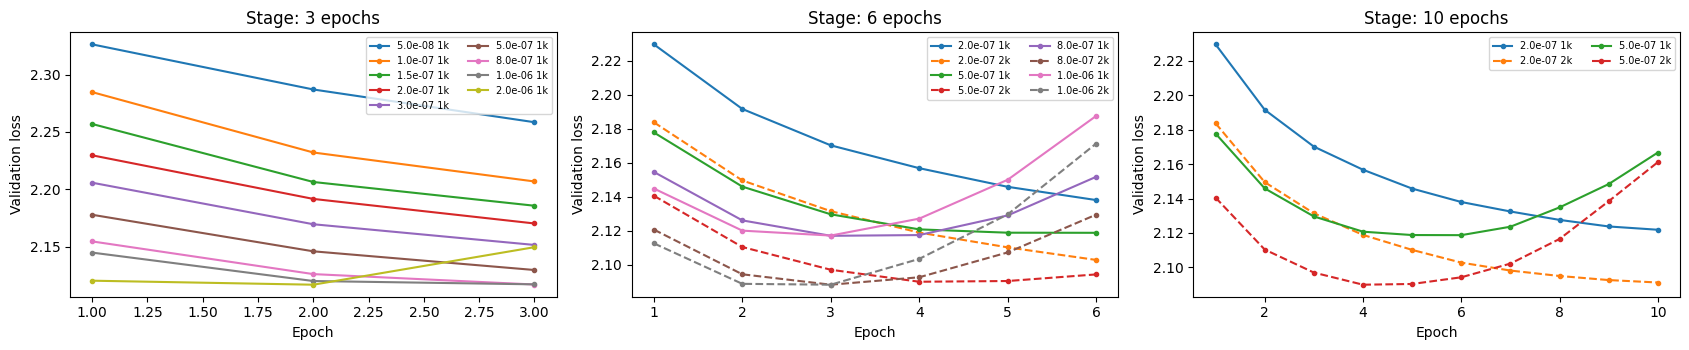

,utterances,lower_WER_lr,other_lr,delta_pp,ci_low_pp,ci_high_pp,baseline_WER,decision,selected_lr
0,60,2e-07,5e-07,-1.205,-2.575,-0.016,3.215,uncertain; expand the panel,-
1,100,2e-07,5e-07,-0.412,-1.474,0.589,4.983,WER unresolved; stability rule (smaller reboun...,2e-07


Selected learning rate: 2e-07; formal comparison: 2e-7 vs 5e-7 at 1k and 2k.
Promotions, bootstrap intervals and the final choice match the saved search record.


In [15]:
early = pd.read_csv(REPORT_DIR / "early_search/summary.csv")
print("Early exploration (motivated the low search range):")
display(early.assign(learning_rate=early.learning_rate.map("{:.0e}".format)).round(4))

if RUN_SEARCH:
    SEARCH = run_search()
else:
    saved = read_json(REPORT_DIR / "search/selection.json")
    validation = REPORT_DIR / "search/validation"
    looks = []
    for count, saved_look in zip(VALIDATION_LOOKS, saved["looks"]):
        panel_ids = [row["utt_id"] for row in validation_panel(count)]
        wer = {}
        for lr in saved["finalist_lrs"]:
            for scale in ("1k", "2k"):
                frame = pd.read_csv(validation / f"{lr_name(lr, scale)}_n{count}.csv")
                wer[lr, scale] = dict(zip(frame.utt_id, frame.wer_percent.astype(float)))
        base = pd.read_csv(validation / f"qwen_base_n{count}.csv").set_index("utt_id").loc[panel_ids]
        look = paired_look([s for s in saved["stages"] if s["budget"] == 10], wer, saved["base_native_losses"],
                           base.wer_percent.astype(float).mean(), panel_ids)
        assert math.isclose(look["ci_high_pp"], saved_look["bootstrap"]["high"]) and look["selected_lr"] == saved_look["selected_lr"]
        looks.append(look)
    SEARCH = dict(stages=saved["stages"], base_native_losses=saved["base_native_losses"], looks=looks,
                  selected_lr=looks[-1]["selected_lr"])
    assert SEARCH["selected_lr"] == saved["selected_lr"]

stage_rows = []
for stage, budget in enumerate(SEARCH_BUDGETS):
    arms = [dict(arm, history=[h for h in arm["history"] if h["epoch"] <= budget]) for arm in SEARCH["stages"] if arm["budget"] == budget]
    ranking = rank_candidates(arms, SEARCH["base_native_losses"])
    kept = promote(ranking, SEARCH_SURVIVORS[stage]) if stage < len(SEARCH_SURVIVORS) else [row["lr"] for row in ranking]
    if stage < len(SEARCH_SURVIVORS):
        assert sorted(kept) == sorted({arm["lr"] for arm in SEARCH["stages"] if arm["budget"] == SEARCH_BUDGETS[stage + 1]})
    stage_rows += [dict(epochs=budget, lr=f"{row['lr']:.1e}", score=row["score"], best_val_loss=row["best_loss"],
                        rebound=row["rebound"], kept=row["lr"] in kept) for row in ranking]
display(pd.DataFrame(stage_rows).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, budget in zip(axes, SEARCH_BUDGETS):
    for arm in (a for a in SEARCH["stages"] if a["budget"] == budget):
        history = pd.DataFrame(arm["history"])
        ax.plot(history.epoch, history.val_loss, "--" if arm["scale"] == "2k" else "-", marker=".",
                label=f"{arm['lr']:.1e} {arm['scale']}")
    ax.set(title=f"Stage: {budget} epochs", xlabel="Epoch", ylabel="Validation loss")
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
looks = pd.DataFrame([{k: v for k, v in look.items() if k != "ranking"} for look in SEARCH["looks"]])
for column in ("lower_WER_lr", "other_lr", "selected_lr"):
    looks[column] = looks[column].map(lambda lr: "-" if lr is None or lr != lr else f"{lr:.0e}")
display(looks.round(3))
FINALISTS = sorted({arm["lr"] for arm in SEARCH["stages"] if arm["budget"] == SEARCH_BUDGETS[-1]})
selected = SEARCH["selected_lr"]
other = next(lr for lr in FINALISTS if lr != selected)
for label, lr, scale in (("expA", selected, "1k"), ("expB", other, "1k"), ("expC", selected, "2k"), ("expD", other, "2k")):
    EXPERIMENTS[label] = dict(name=lr_name(lr, scale), lr=lr, scale=scale)
model_spec.cache_clear()
print(f"Selected learning rate: {selected:.0e}; formal comparison: {lr_text(selected)} vs {lr_text(other)} at 1k and 2k.")
if not RUN_SEARCH:
    print("Promotions, bootstrap intervals and the final choice match the saved search record.")

**14. Training: one call per experiment.**

With `RUN_TRAINING = True` each call trains the model and saves `checkpoints/<model name>/best.pt`. With `RUN_TRAINING = False` it replays the recorded loss history, and every later step loads the reported checkpoint from `SHARED_FOLDER/checkpoints/<expX>/` after checking its SHA-256, learning rate and data size against `qwen_report_data/results/formal_registry.json`.

In [16]:
def run_experiment(label):
    """Train one experiment (RUN_TRAINING) or replay its saved per-epoch history; plot both losses."""
    exp = EXPERIMENTS[label]
    print(f"{label} = {exp['name']}: LR {exp['lr']:g}, {exp['scale']} subset, 20 epochs, effective batch 8")
    if RUN_TRAINING:
        history = pd.DataFrame(train_experiment(CHECKPOINT_DIR / exp["name"], exp["lr"], exp["scale"]))
    else:
        history = pd.read_csv(REPORT_DIR / "results" / f"{label}_history.csv")
        for row, best in zip(history.itertuples(), history.val_loss.cummin()):
            print(f"epoch {row.epoch}/20 train={row.train_loss:.5f} val={row.val_loss:.5f} best={best:.5f}")
    best = history.loc[history.val_loss.idxmin()]
    print(f"Selected checkpoint: epoch {int(best.epoch)} (validation loss {best.val_loss:.5f}); "
          f"{int(history.optimizer_updates.iloc[-1])} updates; {history.seconds.mean() / 60:.1f} min per epoch on the A100.")
    plt.figure(figsize=(7, 3.2))
    plt.plot(history.epoch, history.train_loss, "o-", label="Training loss")
    plt.plot(history.epoch, history.val_loss, "o-", label="Validation loss")
    plt.plot(best.epoch, best.val_loss, "k*", markersize=12, label="Selected checkpoint")
    plt.title(f"{label}: LR {exp['lr']:g}, {exp['scale']} subset")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()
    history.to_csv(RESULTS_DIR / f"{label}_history.csv", index=False)
    return history

**Experiment A (baseline): 1,000 samples, the selected learning rate (`2e-7` in the recorded run).**

expA = qwen_lr2e-7_1k: LR 2e-07, 1k subset, 20 epochs, effective batch 8
epoch 1/20 train=2.27497 val=2.22962 best=2.22962
epoch 2/20 train=2.18173 val=2.19159 best=2.19159
epoch 3/20 train=2.14608 val=2.17017 best=2.17017
epoch 4/20 train=2.12062 val=2.15673 best=2.15673
epoch 5/20 train=2.09858 val=2.14577 best=2.14577
epoch 6/20 train=2.07876 val=2.13797 best=2.13797
epoch 7/20 train=2.05979 val=2.13246 best=2.13246
epoch 8/20 train=2.04158 val=2.12757 best=2.12757
epoch 9/20 train=2.02331 val=2.12376 best=2.12376
epoch 10/20 train=2.00590 val=2.12184 best=2.12184
epoch 11/20 train=1.98897 val=2.11948 best=2.11948
epoch 12/20 train=1.97188 val=2.11882 best=2.11882
epoch 13/20 train=1.95493 val=2.11942 best=2.11882
epoch 14/20 train=1.93800 val=2.11977 best=2.11882
epoch 15/20 train=1.92129 val=2.12201 best=2.11882
epoch 16/20 train=1.90392 val=2.12374 best=2.11882
epoch 17/20 train=1.88675 val=2.12768 best=2.11882
epoch 18/20 train=1.86921 val=2.13027 best=2.11882
epoch 19/20 train=

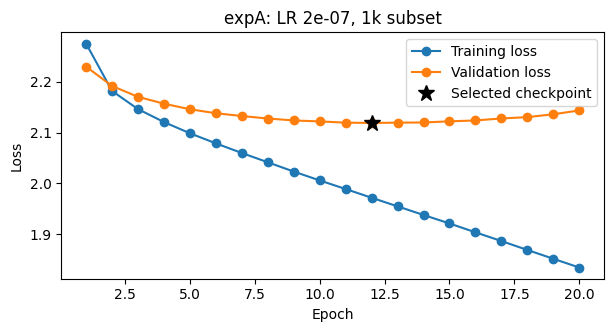

In [17]:
history_expA = run_experiment("expA")

**Experiment B: 1,000 samples, the other finalist learning rate (`5e-7`; learning-rate change vs expA).**

expB = qwen_lr5e-7_1k: LR 5e-07, 1k subset, 20 epochs, effective batch 8
epoch 1/20 train=2.21703 val=2.17776 best=2.17776
epoch 2/20 train=2.12059 val=2.14588 best=2.14588
epoch 3/20 train=2.07201 val=2.12959 best=2.12959
epoch 4/20 train=2.02873 val=2.12072 best=2.12072
epoch 5/20 train=1.98707 val=2.11877 best=2.11877
epoch 6/20 train=1.94678 val=2.11870 best=2.11870
epoch 7/20 train=1.90587 val=2.12361 best=2.11870
epoch 8/20 train=1.86491 val=2.13484 best=2.11870
epoch 9/20 train=1.82313 val=2.14842 best=2.11870
epoch 10/20 train=1.78222 val=2.16674 best=2.11870
epoch 11/20 train=1.74132 val=2.18603 best=2.11870
epoch 12/20 train=1.70095 val=2.21182 best=2.11870
epoch 13/20 train=1.66096 val=2.24240 best=2.11870
epoch 14/20 train=1.62211 val=2.27952 best=2.11870
epoch 15/20 train=1.58522 val=2.31358 best=2.11870
epoch 16/20 train=1.55250 val=2.34807 best=2.11870
epoch 17/20 train=1.52261 val=2.39292 best=2.11870
epoch 18/20 train=1.49511 val=2.42658 best=2.11870
epoch 19/20 train=

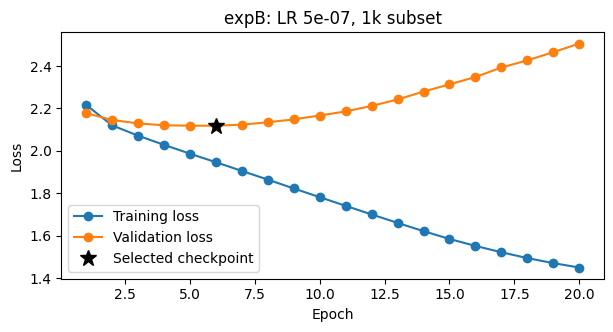

In [18]:
history_expB = run_experiment("expB")

**Experiment C: 2,000 samples, the selected learning rate (`2e-7`; data-size change vs expA).**

expC = qwen_lr2e-7_2k: LR 2e-07, 2k subset, 20 epochs, effective batch 8
epoch 1/20 train=2.23043 val=2.18374 best=2.18374
epoch 2/20 train=2.14497 val=2.14952 best=2.14952
epoch 3/20 train=2.11110 val=2.13143 best=2.13143
epoch 4/20 train=2.08542 val=2.11884 best=2.11884
epoch 5/20 train=2.06308 val=2.11013 best=2.11013
epoch 6/20 train=2.04275 val=2.10273 best=2.10273
epoch 7/20 train=2.02365 val=2.09812 best=2.09812
epoch 8/20 train=2.00533 val=2.09496 best=2.09496
epoch 9/20 train=1.98734 val=2.09259 best=2.09259
epoch 10/20 train=1.96969 val=2.09118 best=2.09118
epoch 11/20 train=1.95224 val=2.09175 best=2.09118
epoch 12/20 train=1.93475 val=2.09170 best=2.09118
epoch 13/20 train=1.91730 val=2.09413 best=2.09118
epoch 14/20 train=1.89962 val=2.09650 best=2.09118
epoch 15/20 train=1.88217 val=2.10032 best=2.09118
epoch 16/20 train=1.86505 val=2.10517 best=2.09118
epoch 17/20 train=1.84741 val=2.11117 best=2.09118
epoch 18/20 train=1.82980 val=2.11679 best=2.09118
epoch 19/20 train=

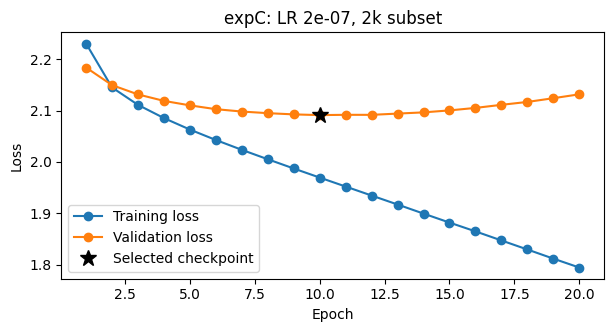

In [19]:
history_expC = run_experiment("expC")

**Experiment D: 2,000 samples, the other finalist learning rate (`5e-7`; learning-rate change vs expC).**

expD = qwen_lr5e-7_2k: LR 5e-07, 2k subset, 20 epochs, effective batch 8
epoch 1/20 train=2.17838 val=2.14052 best=2.14052
epoch 2/20 train=2.08847 val=2.11034 best=2.11034
epoch 3/20 train=2.03918 val=2.09695 best=2.09695
epoch 4/20 train=1.99555 val=2.08990 best=2.08990
epoch 5/20 train=1.95429 val=2.09033 best=2.08990
epoch 6/20 train=1.91306 val=2.09422 best=2.08990
epoch 7/20 train=1.87166 val=2.10217 best=2.08990
epoch 8/20 train=1.83022 val=2.11650 best=2.08990
epoch 9/20 train=1.78854 val=2.13845 best=2.08990
epoch 10/20 train=1.74606 val=2.16116 best=2.08990
epoch 11/20 train=1.70391 val=2.18968 best=2.08990
epoch 12/20 train=1.66202 val=2.22856 best=2.08990
epoch 13/20 train=1.62184 val=2.26706 best=2.08990
epoch 14/20 train=1.58396 val=2.31060 best=2.08990
epoch 15/20 train=1.54917 val=2.35970 best=2.08990
epoch 16/20 train=1.51824 val=2.40968 best=2.08990
epoch 17/20 train=1.49095 val=2.45729 best=2.08990
epoch 18/20 train=1.46801 val=2.50302 best=2.08990
epoch 19/20 train=

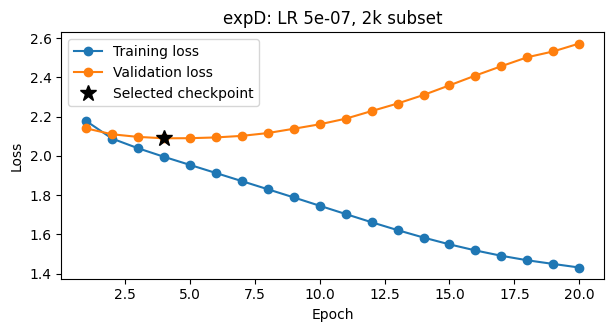

In [20]:
history_expD = run_experiment("expD")

# 1.4 Evaluation, coding practice & attribution (Rubric 1.4)

## 1.4.1 Objective metric (minimum: 1) — report for each experiment
- **Intelligibility — WER, CER, MER (%) ↓:** Whisper `base.en` transcribes the generated audio (step 11). *Mean* = average of per-sentence rates (uncapped); *corpus* = total edits / total reference words (or characters); P95 shows the error tail. Error profile: sentences with WER = 0, sentences with WER > 10%, and substitutions / deletions / insertions per 100 reference words.
- **Latency (s) ↓:** time to synthesise one sentence (timer definitions in step 9); mean, median and P95.
- **Real-time factor (RTF) ↓:** latency / generated audio duration (< 1 is faster than real time); mean, median, P95 and duration-weighted (total time / total audio).
- **Time to first audio (TTFA, ms) ↓:** first-packet latency of the streaming vLLM-Omni backend; PyTorch eager returns the whole waveform at once, so TTFA does not apply.
- **Uncertainty:** 95% confidence intervals are percentile bootstraps over sentences (10,000 resamples, seed 42); backend differences use paired bootstraps on identical sentences. Overlapping intervals mean a difference is not statistically clear.
- **Best values:** in every table the best value of each ranked metric is marked with ★ (also in bold); ↓ lower is better, ↑ higher is better; ties are all marked.

| Panel | Sentences | Generations per model | Purpose |
|---|---|---|---|
| Fixed prompts | 12 new sentences | 5 timed repeats after one warm-up per prompt; first repeat scored | speed and listening |
| CommonTest | the 100-utterance 1k test set | 1 | accuracy on held-out LJSpeech |
| T5Test88 | the 88 sentences of SpeechT5's 100-sentence test set that Qwen never saw | 5, SpeechT5 protocol | Qwen on the sentences SpeechT5 was tested on (the comparison is in the group report) |

**What T5Test88 means.** Our teammates tested SpeechT5 on 100 LJSpeech sentences (*T5Test*). Twelve of them happen to be in Qwen's training or validation split, so testing Qwen on them would be unfair; they are removed and the remaining **88** sentences form *T5Test88*. The name records both where the sentences come from (the SpeechT5 test set) and how many are used (88).

All measurements run on one A100 40 GB with one model loaded at a time.

**15. Evaluation panels.**

Every model is evaluated on the same three panels, and every generation has a fixed seed:

- **Fixed prompts** (`generation`): 12 hand-written sentences with punctuation, numbers, abbreviations and one long sentence, each generated 5 times (60 generations).
- **CommonTest**: the 100 utterances of the seed-42 1k test split, generated once each.
- **T5Test88** (SpeechT5's test sentences that Qwen never saw): the SpeechT5 notebook's 1k test set, rebuilt with the same steps: sample 2,000 with `random_state=42`, split 80/10/10 and take the 100 test utterances. 12 of them appear in a Qwen training or validation split and are removed, leaving 88; each is generated 5 times, as in SpeechT5.

In [ ]:
import re

PROMPTS = [
    "The quick brown fox jumps over the lazy dog.",
    "Adelaide has great weather in spring.",
    "Thank you for listening to this file.",
    "Our group did excellent work on assignment 3.",
    "Can you hear the difference between these 2 voices?",
    "What a great result for our first experiment!",
    "We need clean text, good audio, and enough training time.",
    "The first model was fast; the second model sounded more natural.",
    "I don't believe it is ready, but we will try it again tomorrow.",
    "At the university, Dr. Brown and Mrs. Lee met Mr. Clark.",
    "The class begins at 9 and there are forty-five students in the class.",
    "The model should be able to read new sentences clearly and maintain a consistent reading speed; and pause at the correct location.",
]

def speecht5_test_panel():
    """SpeechT5's 1k test set reproduced from LJSpeech, minus utterances in any Qwen training or validation set."""
    eligible = data[data.duration >= 2.0].reset_index(drop=True)
    sample = eligible.sample(n=2000, random_state=42).reset_index(drop=True)
    _, rest = train_test_split(sample, test_size=0.2, random_state=42, shuffle=True)
    _, test = train_test_split(rest, test_size=0.5, random_state=42, shuffle=True)
    test_1k = test.reset_index(drop=True).sample(n=100, random_state=42).reset_index(drop=True)
    seen = {row["utt_id"] for (scale, role), rows in SPLITS.items() if role != "test" for row in rows}
    panel = test_1k[~test_1k.utt_id.isin(seen)].reset_index(drop=True)
    print(f"SpeechT5 test set: {len(test_1k)} utterances; {len(test_1k) - len(panel)} were in Qwen training/validation "
          f"and are removed; {len(panel)} remain ({panel.utt_id.isin(ids['1k', 'test']).sum()} also in CommonTest).")
    return panel

def evaluation_jobs():
    """Every (panel, sentence, repeat) to synthesise, each with a fixed seed."""
    jobs = [dict(panel="generation", utt_id=f"prompt_{i:02d}", text=clean_text(prompt, numbers=True), seed=42 + i, repeat=r)
            for i, prompt in enumerate(PROMPTS, 1) for r in range(1, 6)]
    jobs += [dict(panel="CommonTest", utt_id=row["utt_id"], text=row["text"], seed=item_seed(row["utt_id"]), repeat=1)
             for row in SPLITS["1k", "test"]]
    jobs += [dict(panel="T5Test88", utt_id=row.utt_id, text=row.text, seed=(item_seed(row.utt_id) + r - 1) % 2**32, repeat=r)
             for row in T5_PANEL.itertuples() for r in range(1, 6)]           # SpeechT5 also used 5 runs per sentence
    return jobs

T5_PANEL = speecht5_test_panel()
assert len(T5_PANEL) == 88
if RUN_EVALUATION:                       # prompt normalisation needs NeMo, installed in Step 1
    JOBS = evaluation_jobs()
    print(f"{len(JOBS)} generations per model: 60 fixed-prompt, 100 CommonTest, 440 T5Test88.")

SpeechT5 test set: 100 utterances; 12 were in Qwen training/validation and are removed; 88 remain (2 also in CommonTest).
600 generations per model: 60 fixed-prompt, 100 CommonTest, 440 T5Test88.


**16. Generation and scoring functions.**

Each model has a state file with one row per generated item (text, seed, WAV hash, timing, transcript, scores). Finished items are reused only when the model, checkpoint hash, recipe, text and seed are identical; everything else is generated.

In [22]:
def job_key(job):
    return f"{job['panel']}/{job['utt_id']}/{job['repeat']}"

def run_identity(spec, backend=INFERENCE_BACKEND):
    """Everything that must match before saved audio or timings can be reused."""
    p = protocol(backend)
    identity = {key: p[key] for key in ("backend", "model_id", "model_revision", "source_revision", "reference_sha256",
                                        "generation", "language", "conditioning", "rate")}
    identity.update(model=spec["name"], checkpoint_sha256=spec["checkpoint_sha256"],
                    warmup="one per pending prompt; one CommonTest warmup if no prompt work")
    if backend == "optimized":
        identity.update(engine=ENGINE_PIN, deployment=engine_deployment(),
                        timer="local HTTP request to first PCM / final PCM; excludes startup, warmup and disk IO")
    else:
        identity["timer"] = "CUDA-synchronized generation + native decode; excludes prepare/CPU transfer/ASR/IO"
    return identity

def run_evaluation(labels, jobs, root, backend=INFERENCE_BACKEND):
    """Generate every missing item on one backend, one model at a time; each WAV and timing is saved immediately."""
    for label in labels:
        spec = model_spec(label)
        name, path = spec["name"], root / "state" / f"{spec['name']}.json"
        state = read_json(path) if path.is_file() else dict(identity=run_identity(spec, backend), rows={})
        if state["identity"] != run_identity(spec, backend):
            raise ValueError(f"{name}: model or recipe differs from {path}; choose a new RUN_DIR.")
        state["jobs"] = jobs
        pending = [job for job in jobs if job_key(job) not in state["rows"]]
        write_json(path, state)
        print(f"{label} ({name}, {BACKEND_NAMES[backend]}): {len(jobs) - len(pending)}/{len(jobs)} ready; "
              f"generating {len(pending)}.", flush=True)
        if not pending:
            continue
        with tts_engine(spec, backend) as generate:
            for job in list({j["utt_id"]: j for j in pending if j["panel"] == "generation"}.values()) or pending[:1]:
                generate(job)                                   # warm-up, not recorded
            for n, job in enumerate(pending, 1):
                pcm, measured = generate(job)
                wav = root / "audio" / f"{name}_{job['utt_id']}_r{job['repeat']:02d}.wav"
                write_wav(wav, pcm)
                state["rows"][job_key(job)] = dict(job, **measured, model=name, wav=wav.relative_to(root).as_posix(),
                    wav_sha256=file_sha256(wav), status="generated", measured_at_utc=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()))
                if n % 25 == 0 or n == len(pending):
                    write_json(path, state)
                    print(f"  {name}: {n}/{len(pending)} generated", flush=True)

def score_evaluation(root):
    """ASR after all TTS engines have stopped: first repeat of prompts and CommonTest, every T5Test88 repeat."""
    import whisper
    states = {path: read_json(path) for path in sorted((root / "state").glob("*.json"))}
    recipe = dict(model="Whisper-base.en", device="cuda", fp16=True, language="en", trim=False, resampling="librosa 24k to 16k",
                  normalization="group NeMo/abbreviation/jiwer", versions={p: version(p) for p in (
                      "openai-whisper", "librosa", "nemo_text_processing", "pynini", "Unidecode", "jiwer", "torch", "numpy")})
    for path, state in states.items():
        if state.setdefault("scoring_identity", recipe) != recipe:
            raise ValueError(f"{path.name} was scored with different package versions; keep the protocols separate.")
    pending = [(path, row) for path, state in states.items() for row in state["rows"].values()
               if row["status"] != "complete" and (row["repeat"] == 1 or row["panel"] == "T5Test88")]
    print(f"Items to transcribe: {len(pending)}")
    if not pending:
        return
    t5_reference = dict(zip(T5_PANEL.utt_id, T5_PANEL.normalised_text.map(t5_clean_text)))
    asr = whisper.load_model("base.en", device="cuda")
    for n, (path, row) in enumerate(pending, 1):
        audio, rate = sf.read(root / row["wav"], dtype="float32")
        if row["panel"] == "T5Test88":
            hypothesis = transcribe(asr, audio, rate, row["seed"], trim=True)
            row.update(t5_reference=t5_reference[row["utt_id"]], scoring="SpeechT5 protocol",
                       wer_percent=t5_wer(t5_reference[row["utt_id"]], hypothesis))
        else:
            hypothesis = transcribe(asr, audio, rate, row["seed"])
            row.update(score_texts(row["text"], hypothesis))
        row.update(asr_text=hypothesis, status="complete", asr_device=recipe["device"],
                   asr_precision="float16" if recipe["fp16"] else "float32",
                   scored_at_utc=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()))
        if n % 50 == 0 or n == len(pending):
            for state_path, state in states.items():
                write_json(state_path, state)
            print(f"ASR {n}/{len(pending)}: {row['model']}/{row['utt_id']} WER {row['wer_percent']:.2f}%", flush=True)

def load_rows(root):
    labels = {exp["name"]: label for label, exp in EXPERIMENTS.items()}
    frame = pd.DataFrame([row for path in sorted((root / "state").glob("*.json")) for row in read_json(path)["rows"].values()])
    frame.insert(0, "experiment", frame.model.map(labels))
    return frame

**17. Generate the audio.**

vLLM-Omni generates all three panels. PyTorch eager generates the fixed prompts and CommonTest with the same checkpoints, sentences and seeds for the backend comparison in step 20 (T5Test88 is vLLM-Omni only).


In [23]:
EVAL_DIR = RUN_DIR / INFERENCE_BACKEND
EAGER_DIR = RUN_DIR / "eager"            # PyTorch eager comparison: fixed prompts and CommonTest
if RUN_EVALUATION:
    run_evaluation(list(EXPERIMENTS), JOBS, EVAL_DIR)
    if EAGER_DIR != EVAL_DIR:
        run_evaluation(list(EXPERIMENTS), [job for job in JOBS if job["panel"] != "T5Test88"], EAGER_DIR, backend="eager")
else:
    print("Evaluation is off (RUN_EVALUATION = False); saved results are read below.")

Base (qwen_base): 160/600 ready (160 reused); generating 440.
EXPORT PASS: qwen_base
ENGINE READY: qwen_base
  qwen_base: 25/440 generated
  qwen_base: 50/440 generated
  qwen_base: 75/440 generated
  qwen_base: 100/440 generated
  qwen_base: 125/440 generated
  qwen_base: 150/440 generated
  qwen_base: 175/440 generated
  qwen_base: 200/440 generated
  qwen_base: 225/440 generated
  qwen_base: 250/440 generated
  qwen_base: 275/440 generated
  qwen_base: 300/440 generated
  qwen_base: 325/440 generated
  qwen_base: 350/440 generated
  qwen_base: 375/440 generated
  qwen_base: 400/440 generated
  qwen_base: 425/440 generated
  qwen_base: 440/440 generated
expA (qwen_lr2e-7_1k): 160/600 ready (160 reused); generating 440.
EXPORT PASS: qwen_lr2e-7_1k
ENGINE READY: qwen_lr2e-7_1k
  qwen_lr2e-7_1k: 25/440 generated
  qwen_lr2e-7_1k: 50/440 generated
  qwen_lr2e-7_1k: 75/440 generated
  qwen_lr2e-7_1k: 100/440 generated
  qwen_lr2e-7_1k: 125/440 generated
  qwen_lr2e-7_1k: 150/440 generated

**18. Transcribe and score.**

Both backends are scored with the same Whisper recipe (GPU, FP16).

In [24]:
if RUN_EVALUATION:
    score_evaluation(EVAL_DIR)
    score_evaluation(EAGER_DIR)
ROWS = load_rows(EVAL_DIR)
EAGER_ROWS = load_rows(EAGER_DIR)
ROWS.to_csv(RESULTS_DIR / f"qwen_{INFERENCE_BACKEND}_per_item.csv", index=False)
EAGER_ROWS.to_csv(RESULTS_DIR / "qwen_eager_per_item.csv", index=False)
display(ROWS.assign(scored=ROWS.status.eq("complete")).groupby(["panel", "experiment"])
        .agg(generated=("wav", "size"), scored=("scored", "sum")).unstack(0))

Items to transcribe: 2200


100%|███████████████████████████████████████| 139M/139M [00:05<00:00, 26.3MiB/s]


ASR 50/2200: qwen_base/LJ002-0065 WER 0.00%
ASR 100/2200: qwen_base/LJ012-0045 WER 0.00%
ASR 150/2200: qwen_base/LJ037-0074 WER 0.00%
ASR 200/2200: qwen_base/LJ049-0152 WER 0.00%
ASR 250/2200: qwen_base/LJ036-0160 WER 0.00%
ASR 300/2200: qwen_base/LJ032-0078 WER 0.00%
ASR 350/2200: qwen_base/LJ002-0219 WER 0.00%
ASR 400/2200: qwen_base/LJ049-0173 WER 8.70%
ASR 450/2200: qwen_lr2e-7_1k/LJ036-0206 WER 0.00%
ASR 500/2200: qwen_lr2e-7_1k/LJ023-0054 WER 11.11%
ASR 550/2200: qwen_lr2e-7_1k/LJ030-0029 WER 0.00%
ASR 600/2200: qwen_lr2e-7_1k/LJ018-0045 WER 4.55%
ASR 650/2200: qwen_lr2e-7_1k/LJ047-0209 WER 0.00%
ASR 700/2200: qwen_lr2e-7_1k/LJ009-0152 WER 0.00%
ASR 750/2200: qwen_lr2e-7_1k/LJ008-0230 WER 0.00%
ASR 800/2200: qwen_lr2e-7_1k/LJ009-0060 WER 0.00%
ASR 850/2200: qwen_lr2e-7_1k/LJ020-0072 WER 0.00%
ASR 900/2200: qwen_lr2e-7_2k/LJ012-0186 WER 25.00%
ASR 950/2200: qwen_lr2e-7_2k/LJ013-0256 WER 4.17%
ASR 1000/2200: qwen_lr2e-7_2k/LJ010-0204 WER 6.25%
ASR 1050/2200: qwen_lr2e-7_2k/LJ016-03

generated                         scored                    
panel      CommonTest T5Test88 generation CommonTest T5Test88 generation
experiment                                                              
Base              100      440         60        100      440         12
expA              100      440         60        100      440         12
expB              100      440         60        100      440         12
expC              100      440         60        100      440         12
expD              100      440         60        100      440         12

**19. Detailed results for every experiment (vLLM-Omni).**

Accuracy uses the scored items (CommonTest: 100 sentences; fixed prompts: first repeat); speed uses every timed generation of the panel (fixed prompts: 5 × 12 per model).



★ best value in each row (↓ lower is better, ↑ higher is better; ties all marked)


★ best value in each row (↓ lower is better, ↑ higher is better; ties all marked)
All five CommonTest WER intervals overlap: no experiment is statistically more intelligible than the others.


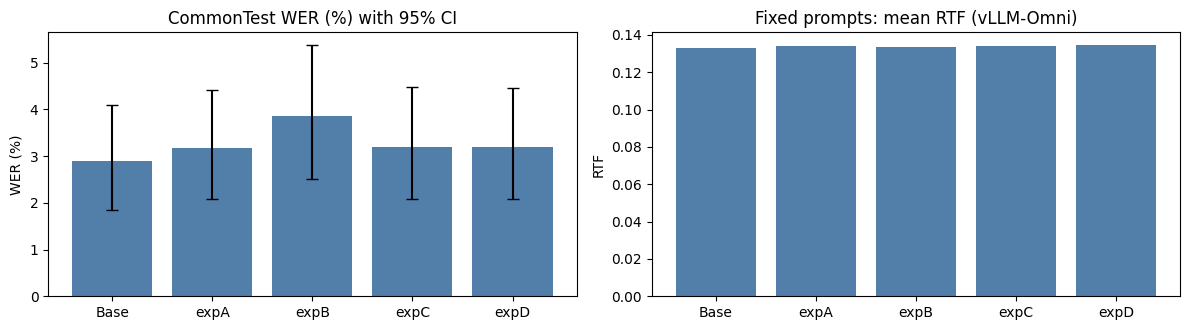

In [37]:
BEST = "font-weight:bold"
UNRANKED = {"Scored sentences", "Timed generations", "Sentences", "Runs", "WER 95% CI low (%)", "WER 95% CI high (%)",
            "Audio duration mean (s)", "Train / val / test", "LR", "Best epoch", "Best validation loss"}
INTEGERS = {"Scored sentences", "Timed generations", "Sentences", "Runs", "Best epoch"}

def mean_ci(values, resamples=10000, seed=42):
    """Mean and 95% percentile-bootstrap interval, resampling sentences."""
    values = np.asarray(values, dtype=float)
    means = np.random.default_rng(seed).choice(values, (resamples, len(values))).mean(axis=1)
    return values.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

def number(value):
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    if isinstance(value, float):
        return "–" if np.isnan(value) else f"{value:.4f}" if abs(value) < 1 else f"{value:.3f}"
    return value

def show_marked(table, best, caption, integer_labels=(), axis=1):
    """Display numbers as text; best values get ★ and bold, so the marking survives any theme or viewer."""
    text = table.copy().astype(object)
    for row in table.index:
        for column in table.columns:
            value, label = table.at[row, column], row if axis == 1 else column
            whole = (label[-1] if isinstance(label, tuple) else label) in integer_labels
            shown = f"{value:,.0f}" if whole and isinstance(value, (int, float)) and value == value else number(value)
            text.at[row, column] = shown + " ★" if best.at[row, column] else shown
    display(text.style.apply(lambda frame: np.where(best, BEST, ""), axis=None).set_caption(caption).set_table_styles(
        [{"selector": "caption", "props": "caption-side:top; font-weight:bold; text-align:left"}]))
    print("★ best value in each", "row" if axis == 1 else "column", "(↓ lower is better, ↑ higher is better; ties all marked)")

def show_table(table, caption, axis=1):
    """Mark the best value of every ranked row (axis=1) or column (axis=0)."""
    def best(series):
        name = series.name[-1] if isinstance(series.name, tuple) else series.name
        values = pd.to_numeric(series, errors="coerce")
        if name in UNRANKED or values.notna().sum() < 2 or values.nunique() == 1:
            return pd.Series(False, index=series.index)
        target = values.max() if "↑" in name else values.min()
        return values.apply(lambda value: bool(np.isclose(value, target)))
    show_marked(table, table.apply(best, axis=axis), caption, INTEGERS, axis)

def speed_metrics(part):
    """Latency, RTF and TTFA over every timed generation of one experiment on one panel."""
    metrics = {
        ("Speed", "Latency mean (s)"): part.seconds.mean(),
        ("Speed", "Latency median (s)"): part.seconds.median(),
        ("Speed", "Latency P95 (s)"): part.seconds.quantile(0.95),
        ("Speed", "RTF mean"): part.rtf.mean(),
        ("Speed", "RTF median"): part.rtf.median(),
        ("Speed", "RTF P95"): part.rtf.quantile(0.95),
        ("Speed", "RTF duration-weighted"): part.seconds.sum() / part.audio_seconds.sum(),
        ("Speed", "TTFA mean (ms)"): 1000 * part.ttfa_seconds.mean(),
        ("Speed", "TTFA P95 (ms)"): 1000 * part.ttfa_seconds.quantile(0.95),
        ("Speed", "Audio duration mean (s)"): part.audio_seconds.mean(),
    }
    if part.repeat.max() > 1:                       # repeated generations of the same sentence
        metrics["Speed", "Within-sentence latency SD (s)"] = part.groupby("utt_id").seconds.std().mean()
        metrics["Speed", "Within-sentence RTF SD"] = part.groupby("utt_id").rtf.std().mean()
    return metrics

def describe(part):
    """Every reported metric of one experiment on one panel."""
    scored = part[part.status == "complete"]
    words = scored.reference_words.sum()
    edits = scored.substitutions + scored.deletions + scored.insertions
    chars = scored.normalized_reference.str.replace(" ", "").str.len()
    wer, low, high = mean_ci(scored.wer_percent)
    metrics = {
        ("Intelligibility", "WER mean (%)"): wer,
        ("Intelligibility", "WER 95% CI low (%)"): low,
        ("Intelligibility", "WER 95% CI high (%)"): high,
        ("Intelligibility", "WER median (%)"): scored.wer_percent.median(),
        ("Intelligibility", "WER P95 (%)"): scored.wer_percent.quantile(0.95),
        ("Intelligibility", "WER corpus (%)"): 100 * edits.sum() / words,
        ("Intelligibility", "CER mean (%)"): scored.cer_percent.mean(),
        ("Intelligibility", "CER corpus (%)"): (scored.cer_percent * chars).sum() / chars.sum(),
        ("Intelligibility", "MER mean (%)"): scored.mer_percent.mean(),
        ("Intelligibility", "MER corpus (%)"): 100 * edits.sum() / (words + scored.insertions.sum()),
        ("Error profile", "Sentences with WER = 0 (%) ↑"): 100 * (scored.wer_percent == 0).mean(),
        ("Error profile", "Sentences with WER > 10 (%)"): 100 * (scored.wer_percent > 10).mean(),
        ("Error profile", "Substitutions per 100 words"): 100 * scored.substitutions.sum() / words,
        ("Error profile", "Deletions per 100 words"): 100 * scored.deletions.sum() / words,
        ("Error profile", "Insertions per 100 words"): 100 * scored.insertions.sum() / words,
        **speed_metrics(part),
        ("Counts", "Scored sentences"): len(scored),
        ("Counts", "Timed generations"): len(part),
    }
    return metrics

DETAIL = {}
for table_no, panel, caption in ((1, "CommonTest", "CommonTest: 100 held-out LJSpeech sentences, one generation each"),
                                (2, "generation", "Fixed prompts: 12 new sentences; accuracy on the first repeat, speed over 5 repeats")):
    part = ROWS[ROWS.panel == panel]
    DETAIL[panel] = pd.DataFrame({label: describe(part[part.experiment == label]) for label in EXPERIMENTS})
    show_table(DETAIL[panel], f"Table {table_no}. {caption} (vLLM-Omni)")
    DETAIL[panel].to_csv(RESULTS_DIR / f"qwen_{INFERENCE_BACKEND}_{panel}_summary.csv")

common = DETAIL["CommonTest"].loc["Intelligibility"].astype(float)
prompts = DETAIL["generation"].loc["Speed"].astype(float)
if common.loc["WER 95% CI low (%)"].max() < common.loc["WER 95% CI high (%)"].min():
    print("All five CommonTest WER intervals overlap: no experiment is statistically more intelligible than the others.")
else:
    print("Some CommonTest WER intervals do not overlap; see Table 1.")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].bar(common.columns, common.loc["WER mean (%)"], color="#527eaa",
            yerr=[common.loc["WER mean (%)"] - common.loc["WER 95% CI low (%)"],
                  common.loc["WER 95% CI high (%)"] - common.loc["WER mean (%)"]], capsize=4)
axes[0].set(title="CommonTest WER (%) with 95% CI", ylabel="WER (%)")
axes[1].bar(prompts.columns, prompts.loc["RTF mean"], color="#527eaa")
axes[1].set(title="Fixed prompts: mean RTF (vLLM-Omni)", ylabel="RTF")
plt.tight_layout()
plt.show()

**20. Inference backends: PyTorch eager vs vLLM-Omni.**

Same checkpoints, sentences and seeds. Accuracy is compared on CommonTest (paired by sentence); speed on the fixed prompts (60 generations per model, paired by prompt and repeat). Software stack, numerical precision (FP32 weights with BF16 compute vs BF16 Talker with FP32 codec) and timer boundaries differ, so this compares two deployments rather than one isolated optimisation. ΔWER is vLLM-Omni minus PyTorch eager; an interval that contains 0 means no statistically clear accuracy difference.


 NeMo-text-processing :: INFO     :: Creating ClassifyFst grammars.
INFO:NeMo-text-processing:Creating ClassifyFst grammars.


★ best value in each row (↓ lower is better, ↑ higher is better; ties all marked)
Paired ΔWER interval excludes 0 for: no experiment | vLLM-Omni latency speed-up: Base 26.2×, expA 26.8×, expB 25.8×, expC 27.2×, expD 27.1×


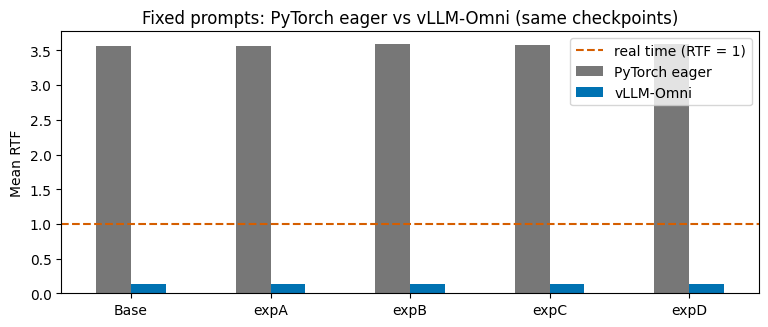

In [38]:
vllm_prompts = ROWS[ROWS.panel == "generation"]
paired = vllm_prompts.merge(EAGER_ROWS[EAGER_ROWS.panel == "generation"], on=["model", "utt_id", "repeat"],
                            suffixes=("", "_eager"))
assert len(paired) == 300 and (paired.text == paired.text_eager).all() and (paired.seed == paired.seed_eager).all()

PT, VL = BACKEND_NAMES["eager"], BACKEND_NAMES["optimized"]
backend_rows, deltas = {}, {}
for label, exp in EXPERIMENTS.items():
    eager_test = EAGER_ROWS[(EAGER_ROWS.panel == "CommonTest") & (EAGER_ROWS.experiment == label)].set_index("utt_id")
    vllm_test = ROWS[(ROWS.panel == "CommonTest") & (ROWS.experiment == label)].set_index("utt_id").loc[eager_test.index]
    delta, low, high = mean_ci(vllm_test.wer_percent - eager_test.wer_percent)
    deltas[label] = (low, high)
    pairs = paired[paired.model == exp["name"]]
    backend_rows[label] = {
        ("CommonTest WER (%)", PT): eager_test.wer_percent.mean(), ("CommonTest WER (%)", VL): vllm_test.wer_percent.mean(),
        ("CommonTest CER (%)", PT): eager_test.cer_percent.mean(), ("CommonTest CER (%)", VL): vllm_test.cer_percent.mean(),
        ("CommonTest MER (%)", PT): eager_test.mer_percent.mean(), ("CommonTest MER (%)", VL): vllm_test.mer_percent.mean(),
        ("ΔWER, paired (pp)", "mean"): delta, ("ΔWER, paired (pp)", "95% CI"): f"{low:.2f} to {high:.2f}",
        ("Latency mean (s)", PT): pairs.seconds_eager.mean(), ("Latency mean (s)", VL): pairs.seconds.mean(),
        ("RTF mean", PT): pairs.rtf_eager.mean(), ("RTF mean", VL): pairs.rtf.mean(),
        ("TTFA mean (ms)", VL): 1000 * pairs.ttfa_seconds.mean(),
        ("Speed-up", "latency ratio (×)"): pairs.seconds_eager.mean() / pairs.seconds.mean(),
    }
BACKEND_TABLE = pd.DataFrame(backend_rows).T

better = pd.DataFrame(False, index=BACKEND_TABLE.index, columns=BACKEND_TABLE.columns)
for metric in ("CommonTest WER (%)", "CommonTest CER (%)", "CommonTest MER (%)", "Latency mean (s)", "RTF mean"):
    pair = BACKEND_TABLE[metric].astype(float)                 # the better backend of each pair, per experiment
    better[[(metric, PT), (metric, VL)]] = pair.eq(pair.min(axis=1), axis=0).to_numpy()
show_marked(BACKEND_TABLE, better, "Table 3. Same checkpoints on two backends: CommonTest accuracy and fixed-prompt speed")
BACKEND_TABLE.to_csv(RESULTS_DIR / "qwen_pytorch_eager_vs_vllm_omni.csv")
clear = [label for label, (low, high) in deltas.items() if low > 0 or high < 0]
print("Paired ΔWER interval excludes 0 for:", ", ".join(clear) if clear else "no experiment",
      "| vLLM-Omni latency speed-up:", ", ".join(f"{label} {value:.1f}×" for label, value in
                                              BACKEND_TABLE["Speed-up", "latency ratio (×)"].items()))

ax = BACKEND_TABLE["RTF mean"].astype(float).plot.bar(figsize=(9, 3.4), color=["#777777", "#0072B2"], rot=0)
ax.axhline(1, color="#D55E00", linestyle="--", label="real time (RTF = 1)")
ax.set(ylabel="Mean RTF", title="Fixed prompts: PyTorch eager vs vLLM-Omni (same checkpoints)")
ax.legend()
plt.show()

**21. Results on T5Test88 (the 88 SpeechT5 test sentences that Qwen never saw).**

Each of the 88 sentences was generated 5 times with different seeds (as in the SpeechT5 experiments) and scored with the SpeechT5 protocol: Whisper `base.en`, silence trimming before ASR, their text cleaning and WER capped at 100%. Per-sentence WER is the mean of its 5 runs; the 95% CI resamples sentences. The comparison with SpeechT5 is reported in the group report.

In [39]:
def describe_t5_panel(part):
    """Qwen results on T5Test88: WER under the SpeechT5 protocol and speed over all 5 runs."""
    per_sentence = part.groupby("utt_id").wer_percent.mean()
    wer, low, high = mean_ci(per_sentence)
    return {
        ("Intelligibility", "WER mean (%)"): wer,
        ("Intelligibility", "WER 95% CI low (%)"): low,
        ("Intelligibility", "WER 95% CI high (%)"): high,
        ("Intelligibility", "WER median (%)"): per_sentence.median(),
        ("Intelligibility", "WER P95 (%)"): per_sentence.quantile(0.95),
        ("Intelligibility", "Sentences with WER = 0 in every run (%) ↑"): 100 * (per_sentence == 0).mean(),
        ("Intelligibility", "Within-sentence WER SD (pp)"): part.groupby("utt_id").wer_percent.std().mean(),
        **speed_metrics(part),
        ("Counts", "Sentences"): part.utt_id.nunique(),
        ("Counts", "Runs"): len(part),
    }

t5_part = ROWS[(ROWS.panel == "T5Test88") & (ROWS.status == "complete")]
T5_TABLE = pd.DataFrame({label: describe_t5_panel(t5_part[t5_part.experiment == label]) for label in EXPERIMENTS})
assert (T5_TABLE.loc["Counts", "Sentences"] == 88).all() and (T5_TABLE.loc["Counts", "Runs"] == 440).all()
show_table(T5_TABLE, "Table 4. T5Test88: 88 SpeechT5 test sentences × 5 runs, SpeechT5 scoring protocol (vLLM-Omni)")
T5_TABLE.to_csv(RESULTS_DIR / "qwen_vllm_T5Test88_metrics.csv")
t5_ci = T5_TABLE.loc["Intelligibility"].astype(float)
if t5_ci.loc["WER 95% CI low (%)"].max() < t5_ci.loc["WER 95% CI high (%)"].min():
    print("All five T5Test88 WER intervals overlap: no experiment is statistically more intelligible than the others.")
else:
    print("Some T5Test88 WER intervals do not overlap; see Table 4.")

★ best value in each row (↓ lower is better, ↑ higher is better; ties all marked)
All five T5Test88 WER intervals overlap: no experiment is statistically more intelligible than the others.


**22. Summary of the controlled experiments.**

One row per experiment: settings, selected checkpoint and key results (vLLM-Omni unless stated). Accuracy is measured on CommonTest and T5Test88, speed on the fixed prompts. Validation losses come from different validation sets (1k vs 2k), so they are reported but not ranked.

In [40]:
summary_rows = {}
for label, exp in EXPERIMENTS.items():
    history = None if label == "Base" else pd.read_csv(RESULTS_DIR / f"{label}_history.csv")
    best = None if history is None else history.loc[history.val_loss.idxmin()]
    common, speed = DETAIL["CommonTest"][label], DETAIL["generation"][label]
    summary_rows[label] = {
        "Train / val / test": "– / – / 100" if label == "Base" else ("800 / 100 / 100" if exp["scale"] == "1k" else "1600 / 200 / 200"),
        "LR": "–" if label == "Base" else f"{exp['lr']:.0e}",
        "Best epoch": "–" if best is None else int(best.epoch),
        "Best validation loss": np.nan if best is None else float(best.val_loss),
        "CommonTest WER (%)": common["Intelligibility", "WER mean (%)"],
        "WER 95% CI low (%)": common["Intelligibility", "WER 95% CI low (%)"],
        "WER 95% CI high (%)": common["Intelligibility", "WER 95% CI high (%)"],
        "CommonTest CER (%)": common["Intelligibility", "CER mean (%)"],
        "CommonTest MER (%)": common["Intelligibility", "MER mean (%)"],
        f"CommonTest WER, {PT} (%)": BACKEND_TABLE.loc[label, ("CommonTest WER (%)", PT)],
        "T5Test88 WER (%)": T5_TABLE.loc[("Intelligibility", "WER mean (%)"), label],
        "Latency mean (s)": speed["Speed", "Latency mean (s)"],
        "RTF mean": speed["Speed", "RTF mean"],
        "TTFA mean (ms)": speed["Speed", "TTFA mean (ms)"],
    }
SUMMARY = pd.DataFrame(summary_rows).T
show_table(SUMMARY, "Table 5. Controlled experiments: settings and key results", axis=0)
SUMMARY.to_csv(RESULTS_DIR / "qwen_experiment_summary.csv")

,Train / val / test,LR,Best epoch,Best validation loss,CommonTest WER (%),WER 95% CI low (%),WER 95% CI high (%),CommonTest CER (%),CommonTest MER (%),"CommonTest WER, PyTorch eager (%)",T5Test88 WER (%),Latency mean (s),RTF mean,TTFA mean (ms)
Base,– / – / 100,–,–,–,2.896 ★,1.845,4.086,1.116,2.863 ★,2.592 ★,3.925,0.5470,0.1331 ★,88.884
expA,800 / 100 / 100,2e-07,12,2.119,3.173,2.075,4.414,1.091,3.085,3.381,3.614 ★,0.5124,0.1342,89.259
expB,800 / 100 / 100,5e-07,6,2.119,3.852,2.502,5.380,1.647,3.691,3.499,3.762,0.5280,0.1337,88.725 ★
expC,1600 / 200 / 200,2e-07,10,2.091,3.200,2.071,4.473,1.329,3.167,2.667,3.897,0.5195,0.1340,89.303
expD,1600 / 200 / 200,5e-07,4,2.090,3.200,2.084,4.464,1.048 ★,3.153,2.703,3.993,0.5100 ★,0.1347,89.436


★ best value in each column (↓ lower is better, ↑ higher is better; ties all marked)


**Figures for the metrics (vLLM-Omni).**

Two views of what the tables report as single numbers. **Left:** the 100 CommonTest sentences of each model grouped by per-sentence WER. Most sentences are transcribed exactly (median WER 0%), so a mean WER of about 3% comes from a small tail of sentences (11–15 per model above 10% in the recorded run), and the tail looks similar for all five models. **Right:** every time-to-first-audio measurement on the fixed prompts; the first audio chunk arrives after about 89 ms for every model, with P95 below 94 ms. The cell only reads `results/qwen_optimized_per_item.csv` (written in step 18), so after Step 1 it can be run on its own.

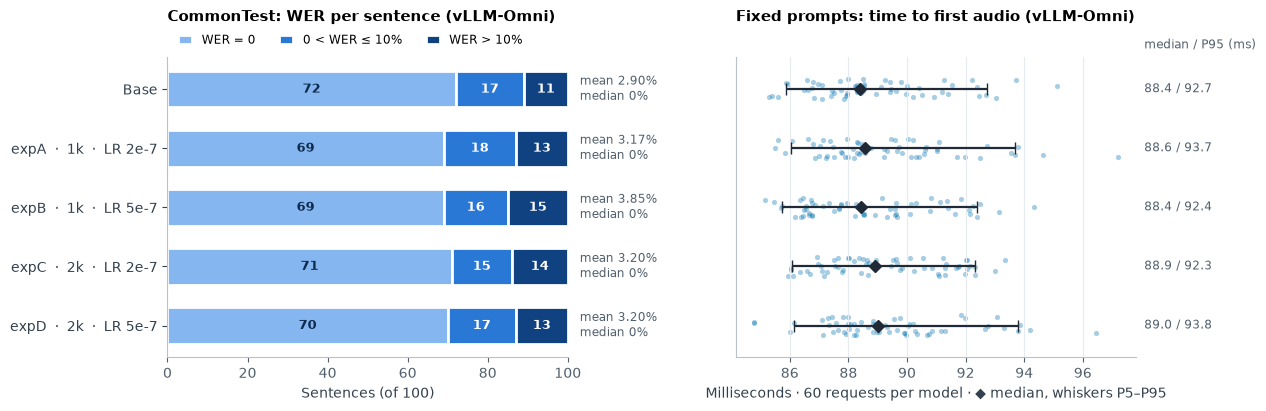

In [2]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt

assert "RESULTS_DIR" in globals(), "Run Step 1 first: it defines the notebook folder and RESULTS_DIR."
per_item = RESULTS_DIR / "qwen_optimized_per_item.csv"            # written by step 18 (vLLM-Omni rows)
if globals().get("INFERENCE_BACKEND", "optimized") != "optimized" or not per_item.is_file():
    print(f"Figure skipped: it needs the vLLM-Omni results of step 18 ({per_item.name} in results/).")
else:
    rows = pd.read_csv(per_item)
    order = ["Base", "expA", "expB", "expC", "expD"]
    names = rows.drop_duplicates("experiment").set_index("experiment").model
    labels = [label if label == "Base" else "{}  ·  {}  ·  LR {}".format(label, *re.search(r"lr([\d.e-]+)_(\dk)", names[label]).groups()[::-1])
              for label in order]
    wer = rows[rows.panel == "CommonTest"].groupby("experiment").wer_percent
    ttfa = rows[rows.panel == "generation"].groupby("experiment").ttfa_seconds
    style = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#B8C2CC",
             "axes.labelcolor": "#33414E", "xtick.color": "#52606D", "ytick.color": "#33414E", "axes.titlesize": 11,
             "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 26}
    with plt.rc_context(style):                                   # local style: later cells keep the defaults
        fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True, gridspec_kw=dict(wspace=0.42))
        bins = [("WER = 0", lambda v: v == 0, "#86B6EF", "#0D2A4F"), ("0 < WER ≤ 10%", lambda v: (v > 0) & (v <= 10), "#2A78D6", "white"),
                ("WER > 10%", lambda v: v > 10, "#104281", "white")]
        for y, label in enumerate(order):
            values, start = wer.get_group(label).to_numpy(), 0
            for name, test, color, ink in bins:
                count = int(test(values).sum())
                left.barh(y, count, left=start, height=0.62, color=color, edgecolor="white", linewidth=2, label=name if y == 0 else None)
                if count >= 4:
                    left.text(start + count / 2, y, str(count), ha="center", va="center", color=ink, fontsize=9.5, weight="bold")
                start += count
            left.text(103, y, f"mean {values.mean():.2f}%\nmedian {np.median(values):.0f}%", va="center", fontsize=8.5, color="#52606D")
        left.set(xlim=(0, 100), xlabel=f"Sentences (of {len(values)})", yticks=range(len(order)), yticklabels=labels)
        left.set_title("CommonTest: WER per sentence (vLLM-Omni)")
        left.legend(ncol=3, frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2)
        rng = np.random.default_rng(0)
        for y, label in enumerate(order):
            values = ttfa.get_group(label).to_numpy() * 1000
            p5, median, p95 = np.percentile(values, [5, 50, 95])
            right.scatter(values, y + rng.uniform(-0.17, 0.17, len(values)), s=14, color="#0072B2", alpha=0.35, linewidths=0)
            right.errorbar(median, y, xerr=[[median - p5], [p95 - median]], fmt="D", color="#1F2A36", ms=6, capsize=4, lw=1.6)
            right.text(1.02, y, f"{median:.1f} / {p95:.1f}", transform=right.get_yaxis_transform(), va="center", fontsize=8.5, color="#52606D")
        right.text(1.02, -0.75, "median / P95 (ms)", transform=right.get_yaxis_transform(), va="center", fontsize=8.5, color="#52606D")
        right.grid(axis="x", color="#E6EBF0", zorder=0)
        right.set(xlabel=f"Milliseconds · {len(values)} requests per model · ◆ median, whiskers P5–P95")
        right.set_title("Fixed prompts: time to first audio (vLLM-Omni)")
        right.tick_params(axis="y", length=0)
        left.invert_yaxis()
        plt.show()

## 1.4.2 Qualitative evaluation (required)
- **Prompts:** the 12 sentences in step 15 (new text, not from LJSpeech), shared with the SpeechT5 experiments; prompt 11 uses the digit `9` and prompt 10 tests abbreviations.
- **Generated WAV files:** `wav_examples/qwen_<experiment>_<backend>_<NN>.wav`, e.g. `qwen_expA_pytorch_01.wav` (PyTorch eager) and `qwen_expA_vllm_01.wav` (vLLM-Omni): 12 prompts × 5 models × 2 backends = 120 files, plus the demo sentence `qwen_expC_demo.wav`. Both are the first repeat of step 17 on each backend (in the saved outputs the PyTorch eager files are those of 26 Oct 2026; see the note at the top).
- **Listening:** the players below play one prompt for every experiment on both backends, and Table 6 lists the transcript and WER of every exported WAV; every model uses the same fixed LJSpeech speaker embedding, so differences come from fine-tuning and deployment only.

**23. Listen and export `wav_examples/`.**

In [2]:
PROMPT_INDEX = 10          # 1-12: this prompt is played for every experiment and backend
first = ROWS[(ROWS.panel == "generation") & (ROWS.repeat == 1)]
eager_first = EAGER_ROWS[(EAGER_ROWS.panel == "generation") & (EAGER_ROWS.repeat == 1)]
exported, transcripts, devices = set(), [], {}
for label, exp in EXPERIMENTS.items():
    eager = eager_first[eager_first.model == exp["name"]].set_index("utt_id")
    vllm = first[first.model == exp["name"]].set_index("utt_id")
    devices[PT], devices[VL] = (eager.asr_device.iloc[0], eager.asr_precision.iloc[0]), (vllm.asr_device.iloc[0], vllm.asr_precision.iloc[0])
    for utt_id in eager.index:
        for backend, path in (("eager", EAGER_DIR / eager.wav[utt_id]), ("optimized", EVAL_DIR / vllm.wav[utt_id])):
            name = f"qwen_{label}_{BACKEND_TAGS[backend]}_{utt_id[-2:]}.wav"
            shutil.copy2(path, WAV_DIR / name)
            exported.add(name)
        transcripts.append({"Prompt": int(utt_id[-2:]), "Experiment": label,
                            f"{PT} WER (%)": eager.wer_percent[utt_id], f"{VL} WER (%)": vllm.wer_percent[utt_id],
                            f"{PT} transcript": eager.asr_text[utt_id].strip(), f"{VL} transcript": vllm.asr_text[utt_id].strip()})
for stale in WAV_DIR.glob("qwen_*_*_[0-9][0-9].wav"):      # copies from an earlier export that used other names
    if stale.name not in exported:
        stale.unlink()

display(pd.DataFrame({"Prompt": range(1, len(PROMPTS) + 1), "Text": PROMPTS}).set_index("Prompt"))
html = [f"<p><b>Prompt {PROMPT_INDEX}:</b> {PROMPTS[PROMPT_INDEX - 1]}</p><table><tr><th>Experiment</th><th>{PT}</th><th>{VL}</th></tr>"]
for label in EXPERIMENTS:
    players = [Audio(filename=str(WAV_DIR / f"qwen_{label}_{BACKEND_TAGS[backend]}_{PROMPT_INDEX:02d}.wav"))._repr_html_()
               for backend in ("eager", "optimized")]
    html.append(f"<tr><td>{label}</td><td>{players[0]}</td><td>{players[1]}</td></tr>")
display(HTML("".join(html) + "</table>"))
TRANSCRIPTS = pd.DataFrame(transcripts).set_index(["Prompt", "Experiment"]).sort_index()
show_table(TRANSCRIPTS, "Table 6. Fixed prompts: Whisper transcript and WER of every exported WAV", axis=0)
TRANSCRIPTS.to_csv(RESULTS_DIR / "qwen_fixed_prompt_transcripts.csv")
print("Whisper base.en device / precision:", {name: "/".join(value) for name, value in devices.items()})
print(len(exported), "labelled WAV files in wav_examples/ (plus the demo sentence)")

,Text
Prompt,
1,The quick brown fox jumps over the lazy dog.
2,Adelaide has great weather in spring.
3,Thank you for listening to this file.
4,Our group did excellent work on assignment 3.
5,Can you hear the difference between these 2 vo...
6,What a great result for our first experiment!
7,"We need clean text, good audio, and enough tra..."
8,The first model was fast; the second model sou...
9,"I don't believe it is ready, but we will try i..."


Experiment,PyTorch eager,vLLM-Omni
Base,Your browser does not support the audio element.,Your browser does not support the audio element.
expA,Your browser does not support the audio element.,Your browser does not support the audio element.
expB,Your browser does not support the audio element.,Your browser does not support the audio element.
expC,Your browser does not support the audio element.,Your browser does not support the audio element.
expD,Your browser does not support the audio element.,Your browser does not support the audio element.


★ best value in each column (↓ lower is better, ↑ higher is better; ties all marked)
Whisper base.en device / precision: {'PyTorch eager': 'cpu/float32', 'vLLM-Omni': 'cuda/float16'}
120 labelled WAV files in wav_examples/ (plus the demo sentence)


**24. Text → WAV demo (Rubric 1.2.4).**

This cell runs after training and evaluation, so it uses the checkpoints trained in this notebook. Change `NEW_TEXT` (and the model label) to try another sentence; it needs a GPU runtime. The saved output below was produced on 30 Oct 2026 with the recorded expC checkpoint, when this cell was still in Section 1.2.

In [12]:
NEW_TEXT = "Our fine-tuned Qwen voice can read any new sentence, such as this one, written on 1 November 2026."
if RUN_DEMO:
    display(Audio(filename=str(text_to_wav(NEW_TEXT, "expC", WAV_DIR / "qwen_expC_demo.wav"))))
else:
    print("Demo is off (RUN_DEMO = False).")

EXPORT PASS: qwen_lr2e-7_2k
ENGINE READY: qwen_lr2e-7_2k


 NeMo-text-processing :: INFO     :: Creating ClassifyFst grammars.
INFO:NeMo-text-processing:Creating ClassifyFst grammars.


expC | optimized | 1.86 s for 8.96 s of audio (RTF 0.208) -> qwen_expC_demo.wav


## 1.4.3 Coding practice & clarity
- One notebook ordered as data → model → training → evaluation; each stage is a function called from a short cell.
- All paths derive from the notebook folder set in Step 1; with the default switches every stage runs from scratch (setting `RUN_SEARCH` / `RUN_TRAINING` to `False` replays the recorded histories in `qwen_report_data/`).
- Reproducibility: seed 42 for splits and training, a fixed seed per generated sentence, pinned model/source/package versions, SHA-256 checkpoint hashes in every run identity, and saved audio reused only when model, recipe, text and seed are identical.

## 1.4.4 Attribution / external resources
- **Dataset:** LJSpeech 1.1 — https://keithito.com/LJ-Speech-Dataset/
- **Model and code:** Qwen3-TTS — https://github.com/QwenLM/Qwen3-TTS, https://huggingface.co/Qwen/Qwen3-TTS-12Hz-0.6B-Base, technical report https://arxiv.org/abs/2601.15621. The input layout in step 7 follows the model's own non-streaming generation prefix.
- **Optimized serving:** vLLM (https://github.com/vllm-project/vllm) and vLLM-Omni (https://github.com/vllm-project/vllm-omni); the deployment settings follow the vLLM-Omni Qwen3-TTS recipe.
- **Evaluation:** OpenAI Whisper `base.en` (https://github.com/openai/whisper), jiwer (https://github.com/jitsi/jiwer), NVIDIA NeMo text processing (https://github.com/NVIDIA/NeMo-text-processing).
- **Libraries:** PyTorch, Transformers, Hugging Face Hub, safetensors, librosa, SoundFile, pandas, scikit-learn, matplotlib.
- **T5Test88 panel:** our teammates' SpeechT5 data split and their text-cleaning / WER protocol.

## 1.4.5 AI use statement
Anthropic Claude helped with debugging, refactoring the notebook into this form and drafting and editing English grammar in Markdown. All AI outputs were verified and confirmed.

# Final verification (before submission)

## Restart & run
- [x] The saved outputs come from a top-to-bottom run on a Colab A100 runtime (30–31 Oct 2026, replay configuration; see the note at the top).
- [ ] A full from-scratch run with the default switches (search, training, both backends) has not been executed for these outputs.
- [x] No hidden local paths: every path derives from the notebook folder (`PROJECT_ROOT`) in Step 1.

## Confirm required artefacts exist
- [x] `wav_examples/` contains 120 labelled WAVs from 12 prompts (plus the demo sentence).
- [x] Objective metrics for each experiment are reported in Section 1.4 (WER, CER, MER, latency, RTF, TTFA; Tables 1–5).
- [x] Dependency files: `requirements.txt` and `qwen_report_data/runtime/engine_requirements.txt`.
- [x] The inference entry point `text_to_wav()` (step 10) takes text and writes a WAV; step 24 demonstrates it.

## Marker instructions
1. **Install:** copy this folder (notebook, `requirements.txt`, `qwen_report_data/`; `LJSpeech-1.1.tar.bz2` is optional and downloaded if absent) to Google Drive, open the notebook in Colab with an A100 GPU, set `NOTEBOOK_FOLDER` in Step 1 to that folder and run Step 1; it authorises Drive and installs the pinned packages.
2. **Reported checkpoints (no training):** open the shared folder `GenAI_3_Checkpoints` (<https://drive.google.com/drive/folders/1gMHQJ8O9UIm3ZoDJEVk9b9s0HpJrW1Gh>; four `best.pt` files of 3.6 GB and the saved vLLM-Omni evaluation records, 0.9 GB) and add it to My Drive with **Organise → Add shortcut → My Drive**; a shortcut uses none of your storage. In Step 1 set `RUN_SEARCH = False` and `RUN_TRAINING = False` and keep `SHARED_FOLDER`, then run the cells in order. Step 1 copies the evaluation records next to the notebook, the search and training cells replay the recorded histories, and later steps load the shared checkpoints and stop if one differs from the recorded SHA-256. Saved vLLM-Omni items are reused because checkpoint, text and seed match; PyTorch eager audio for the backend comparison (step 20) is generated again (about 4–5 A100 hours).
3. **Training from scratch:** keep the default switches (`True`). The search and the four training runs run first; checkpoints need about 130 GB of free space at the peak of the search.
4. **Inference:** change `NEW_TEXT` in step 24, or call `text_to_wav("...", "expC", WAV_DIR / "out.wav")`.
5. **Results:** tables in Section 1.4, CSV files in `results/`, audio in `wav_examples/`.


In [42]:
counts = ROWS.groupby(["panel", "experiment"]).agg(items=("wav", "size"), scored=("status", lambda s: (s == "complete").sum()))
checks = {
    "splits reproduce the saved seed-42 manifests": True,               # asserted in step 4
    "search: 9 -> 4 -> 2 candidates; expA and expC use the selected LR": (
        [len({arm["lr"] for arm in SEARCH["stages"] if arm["budget"] == b}) for b in SEARCH_BUDGETS] == [9, 4, 2]
        and EXPERIMENTS["expA"]["lr"] == EXPERIMENTS["expC"]["lr"] == SEARCH["selected_lr"]),
    "four 20-epoch training histories": all(len(pd.read_csv(RESULTS_DIR / f"{label}_history.csv")) == 20
                                            for label in EXPERIMENTS if label != "Base"),
    "fixed prompts: 60 timings and 12 scores per model": (counts.loc["generation"] == [60, 12]).all().all(),
    "CommonTest: 100 scores per model": (counts.loc["CommonTest"] == 100).all().all(),
    "T5Test88: 440 scores per model": (counts.loc["T5Test88"] == 440).all().all(),
    "wav_examples: 120 labelled WAVs": len(list(WAV_DIR.glob("qwen_*_*_[0-9][0-9].wav"))) == 120,
}
display(pd.DataFrame([dict(check=name, result="PASS" if ok else "FAIL") for name, ok in checks.items()]))

,check,result
0,splits reproduce the saved seed-42 manifests,PASS
1,"search decisions reproduced (9 -> 4 -> 2, LR 2...",PASS
2,four 20-epoch training histories,PASS
3,fixed prompts: 60 timings and 12 scores per model,PASS
4,CommonTest: 100 scores per model,PASS
5,T5Test88: 440 scores per model,PASS
6,wav_examples: 120 labelled WAVs,PASS
